# Price-model diagnostics

Review matching full-data checkpoints; unfinished estimators remain pending. Training artifacts stay read-only. Reports and explanation caches use `MODEL_OUTPUT/diagnostics/model_evaluations/`. PCR adds one full-feature model with 31 PCs; flags and categories bypass PCA.

## 1. Setup and methods

**Population:** retained advertised listings, including new and used vehicles; this is not a transaction-price benchmark. Models fit `ln(price)` and predict USD. Family-separated held-out rows test transfer to unseen vehicle families. Validation predictions come from tuning fits; test predictions come from final refits on fit + validation rows, so their errors are not a paired overfitting estimate.

| Feature set | Predictors |
| --- | --- |
| base | Listing attributes and deterministic derived fields |
| enhanced | Base + selected vPIC specifications |
| enhanced_safety | Enhanced + structured safety, complaints, recalls |
| full | Enhanced safety + YouTube + DougScore predictors |

**Key assumptions:** enrichment timing remains retrospective. Require matching protocol and shared source hashes; additional full-feature source files can change the combined fingerprint. Independently require identical VINs, actual prices, decoded `Make`, and family blocks in each evaluation partition. `Make` comes from saved vPIC-linked receipts, with source linkage on lowercase `vin`; `ModelYear`, `Make`, `Model`, and `Trim` remain separate fields. These observational errors do not measure causal make effects.

**Definitions:** MSE = mean squared USD error (USD²); RMSE = √MSE (USD); MAE = mean absolute USD error; R² = 1 − SSE/SST within the evaluated population. Negative R² is retained; singleton or constant-price groups have undefined R². WAPE = 100 × sum absolute error / sum actual price. Average price is the arithmetic mean of **held-out advertised prices**, not the whole market.

**PCR comparison:** the new estimator has a different code fingerprint. Only PCR may supplement the original suite across that difference, after exact full-source/schema, split, package, target, weighting and tuning-budget checks. Its unused tree budget may differ. Held-out VIN/label/Make/family receipts must still match exactly; the original eight estimators retain strict code checks.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import sys
import importlib
import json
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from matplotlib.colors import LogNorm
from IPython.display import display, Markdown, HTML

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'MODELS' / 'price_data_diagnostics.py').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'MODELS' / 'price_data_diagnostics.py').is_file():
    raise FileNotFoundError('Run from the project checkout or set PROJECT_ROOT explicitly.')
sys.path.insert(0, str(PROJECT_ROOT))
from MODELS import Price_ML_Models as price_module
from MODELS import price_model_diagnostics as diagnostics_module
importlib.reload(price_module)
importlib.reload(diagnostics_module)
from MODELS.price_model_diagnostics import (
    FEATURE_SETS, MODELS, TREE_MODELS, models_for_variant, discover_checkpoints,
    collect_evaluations, collect_importance,
)

MODEL_ROOT = PROJECT_ROOT / 'MODEL_OUTPUT'
REVIEW_DIR = MODEL_ROOT / 'diagnostics' / 'model_evaluations'
REVIEW_DIR.mkdir(parents=True, exist_ok=True)
RUN_OVERRIDES = {}  # Optional: {'full': [Path('/absolute/path/to/run')]}; preserves protocol checks.
FOREST_IMPORTANCE_METHOD = 'impurity'  # 'shap' enables costly exact RF SHAP.
FOREST_EXPLANATION_ROWS = 20  # Exact SHAP for large forests; increase for ranking stability.
EXPLANATION_ROWS = 100  # First 100 of the frozen random test sample; no source resampling.
MAKE_PLOT_MODEL = 'catboost'  # Fixed presentation choice, not selected from test errors.
SPOTLIGHT_MAKES = ['TOYOTA', 'FERRARI']
RUN_PREFLIGHT = False  # Reuse the last source preflight; True explicitly refreshes it.

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
COLORS = {'base': '#315E88', 'enhanced': '#A77925',
          'enhanced_safety': '#9A4C24', 'full': '#74618C'}
MODEL_LABELS = {'multiple_linear_regression': 'Linear regression', 'random_forest': 'Random forest',
                'elastic_net': 'Elastic net', 'catboost': 'CatBoost', 'lightgbm': 'LightGBM',
                'xgboost': 'XGBoost', 'lasso': 'Lasso', 'ridge': 'Ridge', 'pcr': 'PCR (31 PCs)'}

def formatted(table):
    formats = {c: '{:,.2f}' for c in table.select_dtypes(include='number').columns}
    for c in ['r2', 'test_r2']:
        if c in table: formats[c] = '{:.3f}'
    for c in ['rows', 'family_blocks']:
        if c in table: formats[c] = '{:,.0f}'
    return table.style.format(formats, na_rep='—')

selected, model_status, run_inventory = discover_checkpoints(MODEL_ROOT, RUN_OVERRIDES)
metrics, make_metrics, evaluations = collect_evaluations(selected, REVIEW_DIR)
test_metrics = metrics.query("partition == 'test'").copy()
validation_metrics = metrics.query("partition == 'validation'").copy()
snapshot = datetime.now(timezone.utc).isoformat()
model_status.to_csv(REVIEW_DIR / 'model_status.csv', index=False)
run_inventory.to_csv(REVIEW_DIR / 'run_inventory.csv', index=False)
print(f'Reviewed {len(selected)} completed checkpoints at {snapshot}; tables: {REVIEW_DIR}')

Reviewed 28 completed checkpoints at 2026-10-24T19:12:12.969794+00:00; tables: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\diagnostics\model_evaluations


## 2. Results at a glance

In [2]:
completed = model_status.query("status == 'completed checkpoint'").groupby('feature_set').size()
display(pd.DataFrame({'completed': completed.reindex(FEATURE_SETS, fill_value=0), 'expected': pd.Series({v: len(models_for_variant(v)) for v in FEATURE_SETS})}))
best_validation = validation_metrics.loc[validation_metrics.groupby('feature_set').mae.idxmin()]
display(formatted(best_validation[['feature_set', 'model', 'rows', 'mse', 'rmse', 'mae', 'r2']]))
pending = model_status.query("status != 'completed checkpoint'")
if len(pending):
    display(Markdown('**Pending:** ' + '; '.join(f"{v}: {', '.join(g.model)}" for v, g in pending.groupby('feature_set'))))
display(run_inventory.query('compatible')[['feature_set', 'run', 'run_status', 'source_files', 'reason']].reset_index(drop=True))

pcr_key = ('full', 'pcr')
if pcr_key in selected:
    pcr_run, pcr_metadata, _ = selected[pcr_key]
    pcr_summary = pcr_metadata['models']['pcr']['pca_summary']
    display(Markdown(f"**PCR:** 31 components; {len(pcr_summary['retained_numerical_fields'])} numerical fields; final-training numerical variance retained {pcr_summary['cumulative_explained_variance']:.2%}. Saved run: `{pcr_run}`."))
else:
    display(Markdown('**PCR (31 PCs), full only:** pending. Run the full-feature PCR command in README, then rerun this notebook. This notebook never trains it.'))

,completed,expected
base,8,8
enhanced,8,8
enhanced_safety,8,8
full,4,9


,feature_set,model,rows,mse,rmse,mae,r2
0,base,catboost,"100,000","63,201,910.87","7,949.96","2,586.08",0.816
16,enhanced,catboost,"100,000","64,122,508.76","8,007.65","2,677.65",0.814
32,enhanced_safety,catboost,"100,000","64,078,624.85","8,004.91","2,673.50",0.814
48,full,catboost,"100,000","65,446,804.97","8,089.92","2,666.52",0.810


**Pending:** full: random_forest, multiple_linear_regression, lasso, ridge, elastic_net

,feature_set,run,run_status,source_files,reason
0,base,E:\DataScience_Capstone_Cars\MODEL_OUTPUT\base...,completed,5,matched protocol and shared sources
1,enhanced,E:\DataScience_Capstone_Cars\MODEL_OUTPUT\enha...,completed,5,matched protocol and shared sources
2,enhanced_safety,E:\DataScience_Capstone_Cars\MODEL_OUTPUT\enha...,running,5,matched protocol and shared sources
3,enhanced_safety,E:\DataScience_Capstone_Cars\MODEL_OUTPUT\enha...,completed,5,matched protocol and shared sources
4,full,E:\DataScience_Capstone_Cars\MODEL_OUTPUT\full...,running,11,matched protocol and shared sources
5,full,E:\DataScience_Capstone_Cars\MODEL_OUTPUT\full...,completed,11,PCR-only supplement: matched full sources/sche...


**PCR:** 31 components; 88 numerical fields; final-training numerical variance retained 85.28%. Saved run: `E:\DataScience_Capstone_Cars\MODEL_OUTPUT\full\20261024T154353886346Z-full`.

## 3. Estimator metrics

Metrics use ordinary listing weights and reconcile to saved scores. MSE is computed from individual USD residuals.

In [3]:
for partition, table in [('Test — final refits', test_metrics), ('Validation — tuning fits', validation_metrics)]:
    display(Markdown(f'### {partition}'))
    view = model_status[['feature_set', 'model', 'status']].merge(
        table[['feature_set', 'model', 'rows', 'mse', 'rmse', 'mae', 'r2']],
        on=['feature_set', 'model'], how='left', validate='one_to_one')
    display(formatted(view))

### Test — final refits

,feature_set,model,status,rows,mse,rmse,mae,r2
0,base,catboost,completed checkpoint,"576,422","65,763,257.94","8,109.45","2,409.52",0.847
1,base,lightgbm,completed checkpoint,"576,422","80,714,640.01","8,984.13","2,726.79",0.812
2,base,xgboost,completed checkpoint,"576,422","91,092,598.61","9,544.24","2,993.65",0.788
3,base,random_forest,completed checkpoint,"576,422","80,575,086.13","8,976.36","3,011.22",0.812
4,base,multiple_linear_regression,completed checkpoint,"576,422","146,159,997.99","12,089.66","4,101.87",0.660
5,base,lasso,completed checkpoint,"576,422","143,871,443.31","11,994.64","4,652.77",0.665
6,base,ridge,completed checkpoint,"576,422","121,944,735.78","11,042.86","3,837.96",0.716
7,base,elastic_net,completed checkpoint,"576,422","139,938,527.26","11,829.56","4,492.73",0.674
8,enhanced,catboost,completed checkpoint,"576,422","71,241,881.07","8,440.49","2,604.96",0.834
9,enhanced,lightgbm,completed checkpoint,"576,422","84,568,586.04","9,196.12","2,740.69",0.803


### Validation — tuning fits

,feature_set,model,status,rows,mse,rmse,mae,r2
0,base,catboost,completed checkpoint,"100,000","63,201,910.87","7,949.96","2,586.08",0.816
1,base,lightgbm,completed checkpoint,"100,000","78,136,690.74","8,839.50","2,991.54",0.773
2,base,xgboost,completed checkpoint,"100,000","89,090,585.07","9,438.78","3,152.93",0.741
3,base,random_forest,completed checkpoint,"100,000","80,495,536.21","8,971.93","3,187.87",0.766
4,base,multiple_linear_regression,completed checkpoint,"100,000","91,725,313.04","9,577.33","3,824.58",0.734
5,base,lasso,completed checkpoint,"100,000","114,877,422.20","10,718.09","4,323.08",0.666
6,base,ridge,completed checkpoint,"100,000","90,820,498.52","9,529.98","3,818.76",0.736
7,base,elastic_net,completed checkpoint,"100,000","111,972,884.03","10,581.72","4,257.95",0.675
8,enhanced,catboost,completed checkpoint,"100,000","64,122,508.76","8,007.65","2,677.65",0.814
9,enhanced,lightgbm,completed checkpoint,"100,000","77,596,490.00","8,808.89","2,990.34",0.775


### Matched test performance

Color scales are panel-specific. Blank cells are pending; PCR applies only to `full`.

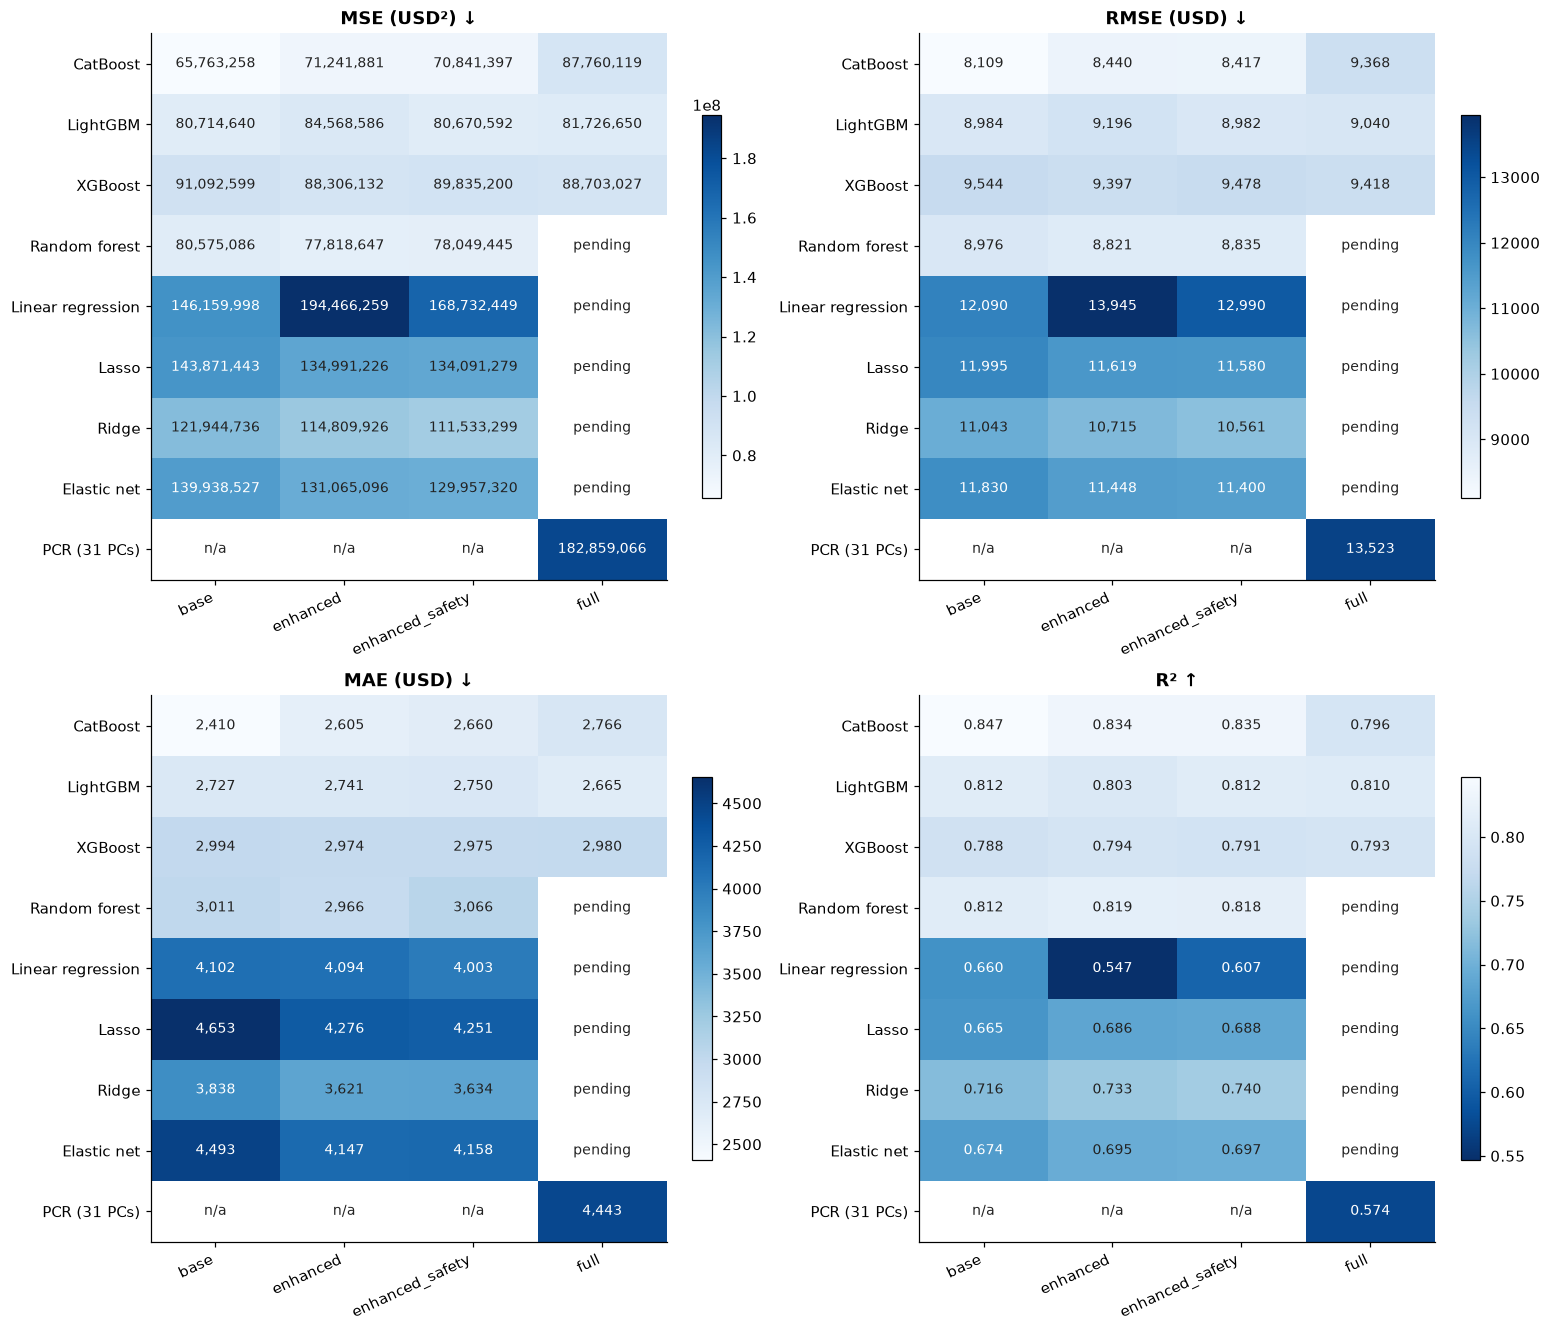

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)
for ax, metric, title in zip(axes.flat, ['mse', 'rmse', 'mae', 'r2'],
                            ['MSE (USD²) ↓', 'RMSE (USD) ↓', 'MAE (USD) ↓', 'R² ↑']):
    matrix = test_metrics.pivot(index='model', columns='feature_set', values=metric).reindex(index=MODELS, columns=FEATURE_SETS)
    im = ax.imshow(np.ma.masked_invalid(matrix.to_numpy()), aspect='auto', cmap='Blues' if metric != 'r2' else 'Blues_r')
    ax.set_xticks(range(len(FEATURE_SETS)), FEATURE_SETS, rotation=25, ha='right')
    ax.set_yticks(range(len(MODELS)), [MODEL_LABELS[m] for m in MODELS])
    ax.set_title(title)
    for (i, j), value in np.ndenumerate(matrix.to_numpy()):
        label = ('n/a' if MODELS[i] == 'pcr' and FEATURE_SETS[j] != 'full' else 'pending') if pd.isna(value) else f'{value:.3f}' if metric == 'r2' else f'{value:,.0f}'
        norm = im.norm(value) if pd.notna(value) else 0
        dark = pd.notna(value) and (norm > .55 if metric != 'r2' else norm < .45)
        ax.text(j, i, label, ha='center', va='center', color='white' if dark else '#222222', fontsize=9)
    fig.colorbar(im, ax=ax, shrink=.7)
plt.show()

### Model evaluations

Bias is predicted minus actual price. Positive MAE reduction improves on the training-median baseline. The 95% MAE intervals resample whole family blocks (200 draws); they are not pairwise significance tests.

In [5]:
display(formatted(evaluations[['feature_set', 'model', 'test_mae', 'test_r2',
    'mae_reduction_vs_median_pct', 'bias_usd', 'p95_error_usd',
    'mae_family_bootstrap_low', 'mae_family_bootstrap_high', 'tree_cap_reached', 'evaluation']]))


,feature_set,model,test_mae,test_r2,mae_reduction_vs_median_pct,bias_usd,p95_error_usd,mae_family_bootstrap_low,mae_family_bootstrap_high,tree_cap_reached,evaluation
0,base,catboost,"2,409.52",0.847,81.44,-76.36,"7,119.19","2,158.00","2,683.89",False,Positive held-out R²
1,base,lightgbm,"2,726.79",0.812,79.00,-822.24,"7,813.54","2,391.11","3,142.62",False,Positive held-out R²
2,base,xgboost,"2,993.65",0.788,76.94,-686.44,"8,639.93","2,687.03","3,421.31",False,Positive held-out R²
3,base,random_forest,"3,011.22",0.812,76.81,-208.89,"9,090.17","2,654.80","3,419.79",False,Positive held-out R²
4,base,multiple_linear_regression,"4,101.87",0.660,68.41,-418.15,"12,356.84","3,342.84","5,131.05",False,Positive held-out R²
5,base,lasso,"4,652.77",0.665,64.16,-974.89,"14,308.49","4,109.51","5,388.49",False,Positive held-out R²
6,base,ridge,"3,837.96",0.716,70.44,-675.29,"11,922.00","3,269.08","4,670.49",False,Positive held-out R²
7,base,elastic_net,"4,492.73",0.674,65.40,-853.29,"13,536.75","3,985.64","5,213.09",False,Positive held-out R²
8,enhanced,catboost,"2,604.96",0.834,79.94,-298.33,"7,803.88","2,353.23","2,904.09",False,Positive held-out R²
9,enhanced,lightgbm,"2,740.69",0.803,78.89,-738.26,"7,745.14","2,403.02","3,284.96",False,Positive held-out R²


**base:** across 8 completed estimators, test MAE ranges from $2,410 to $4,653; R² ranges from 0.660 to 0.847. These ranges describe the available models, not evidence that extra sources improve every estimator.

**enhanced:** across 8 completed estimators, test MAE ranges from $2,605 to $4,276; R² ranges from 0.547 to 0.834. These ranges describe the available models, not evidence that extra sources improve every estimator.

**enhanced_safety:** across 8 completed estimators, test MAE ranges from $2,660 to $4,251; R² ranges from 0.607 to 0.835. These ranges describe the available models, not evidence that extra sources improve every estimator.

**full:** across 4 completed estimators, test MAE ranges from $2,665 to $4,443; R² ranges from 0.574 to 0.810. These ranges describe the available models, not evidence that extra sources improve every estimator.

## 4. Top variables

Boosters use path-dependent SHAP on `ln(price)` for 100 frozen test rows, with additive reconstruction checks. Forests default to global impurity importance, which favors fields with more split opportunities. Optional exact tree-averaged forest SHAP uses `FOREST_IMPORTANCE_METHOD="shap"` and `FOREST_EXPLANATION_ROWS`; it can take tens of minutes. Background-based forest SHAP crashes in this Windows runtime.

Linear coefficients apply to standardized numeric fields and encoded categories. Correlation and full one-hot coding complicate interpretation. PCR coefficients refer to components, not original fields. Magnitudes across these methods are not comparable or causal. Caches bind predictor/input hashes, method, and sample size.

In [6]:
importance, explanation_status = collect_importance(selected, REVIEW_DIR / 'explanations', rows=EXPLANATION_ROWS, forest_rows=FOREST_EXPLANATION_ROWS, forest_method=FOREST_IMPORTANCE_METHOD)
importance.to_csv(REVIEW_DIR / 'importance.csv', index=False)
explanation_status.to_json(REVIEW_DIR / 'explanations.json', orient='records', indent=2)
display(explanation_status[[c for c in ['feature_set', 'model', 'status', 'method', 'sample_rows', 'error'] if c in explanation_status]])

Explaining base / catboost


Explaining base / lightgbm


Explaining base / xgboost


Explaining base / random_forest


Explaining base / multiple_linear_regression


...

Explaining full / catboost


Explaining full / lightgbm


Explaining full / xgboost


Explaining full / pcr


,feature_set,model,status,method,sample_rows
0,base,catboost,completed,native path-dependent TreeSHAP,100.0
1,base,lightgbm,completed,native path-dependent TreeSHAP,100.0
2,base,xgboost,completed,native path-dependent TreeSHAP,100.0
3,base,random_forest,completed,fitted global normalized impurity importance (...,NaN
4,base,multiple_linear_regression,completed,signed coefficient (standardized numeric / one...,NaN
5,base,lasso,completed,signed coefficient (standardized numeric / one...,NaN
6,base,ridge,completed,signed coefficient (standardized numeric / one...,NaN
7,base,elastic_net,completed,signed coefficient (standardized numeric / one...,NaN
8,enhanced,catboost,completed,native path-dependent TreeSHAP,100.0
9,enhanced,lightgbm,completed,native path-dependent TreeSHAP,100.0


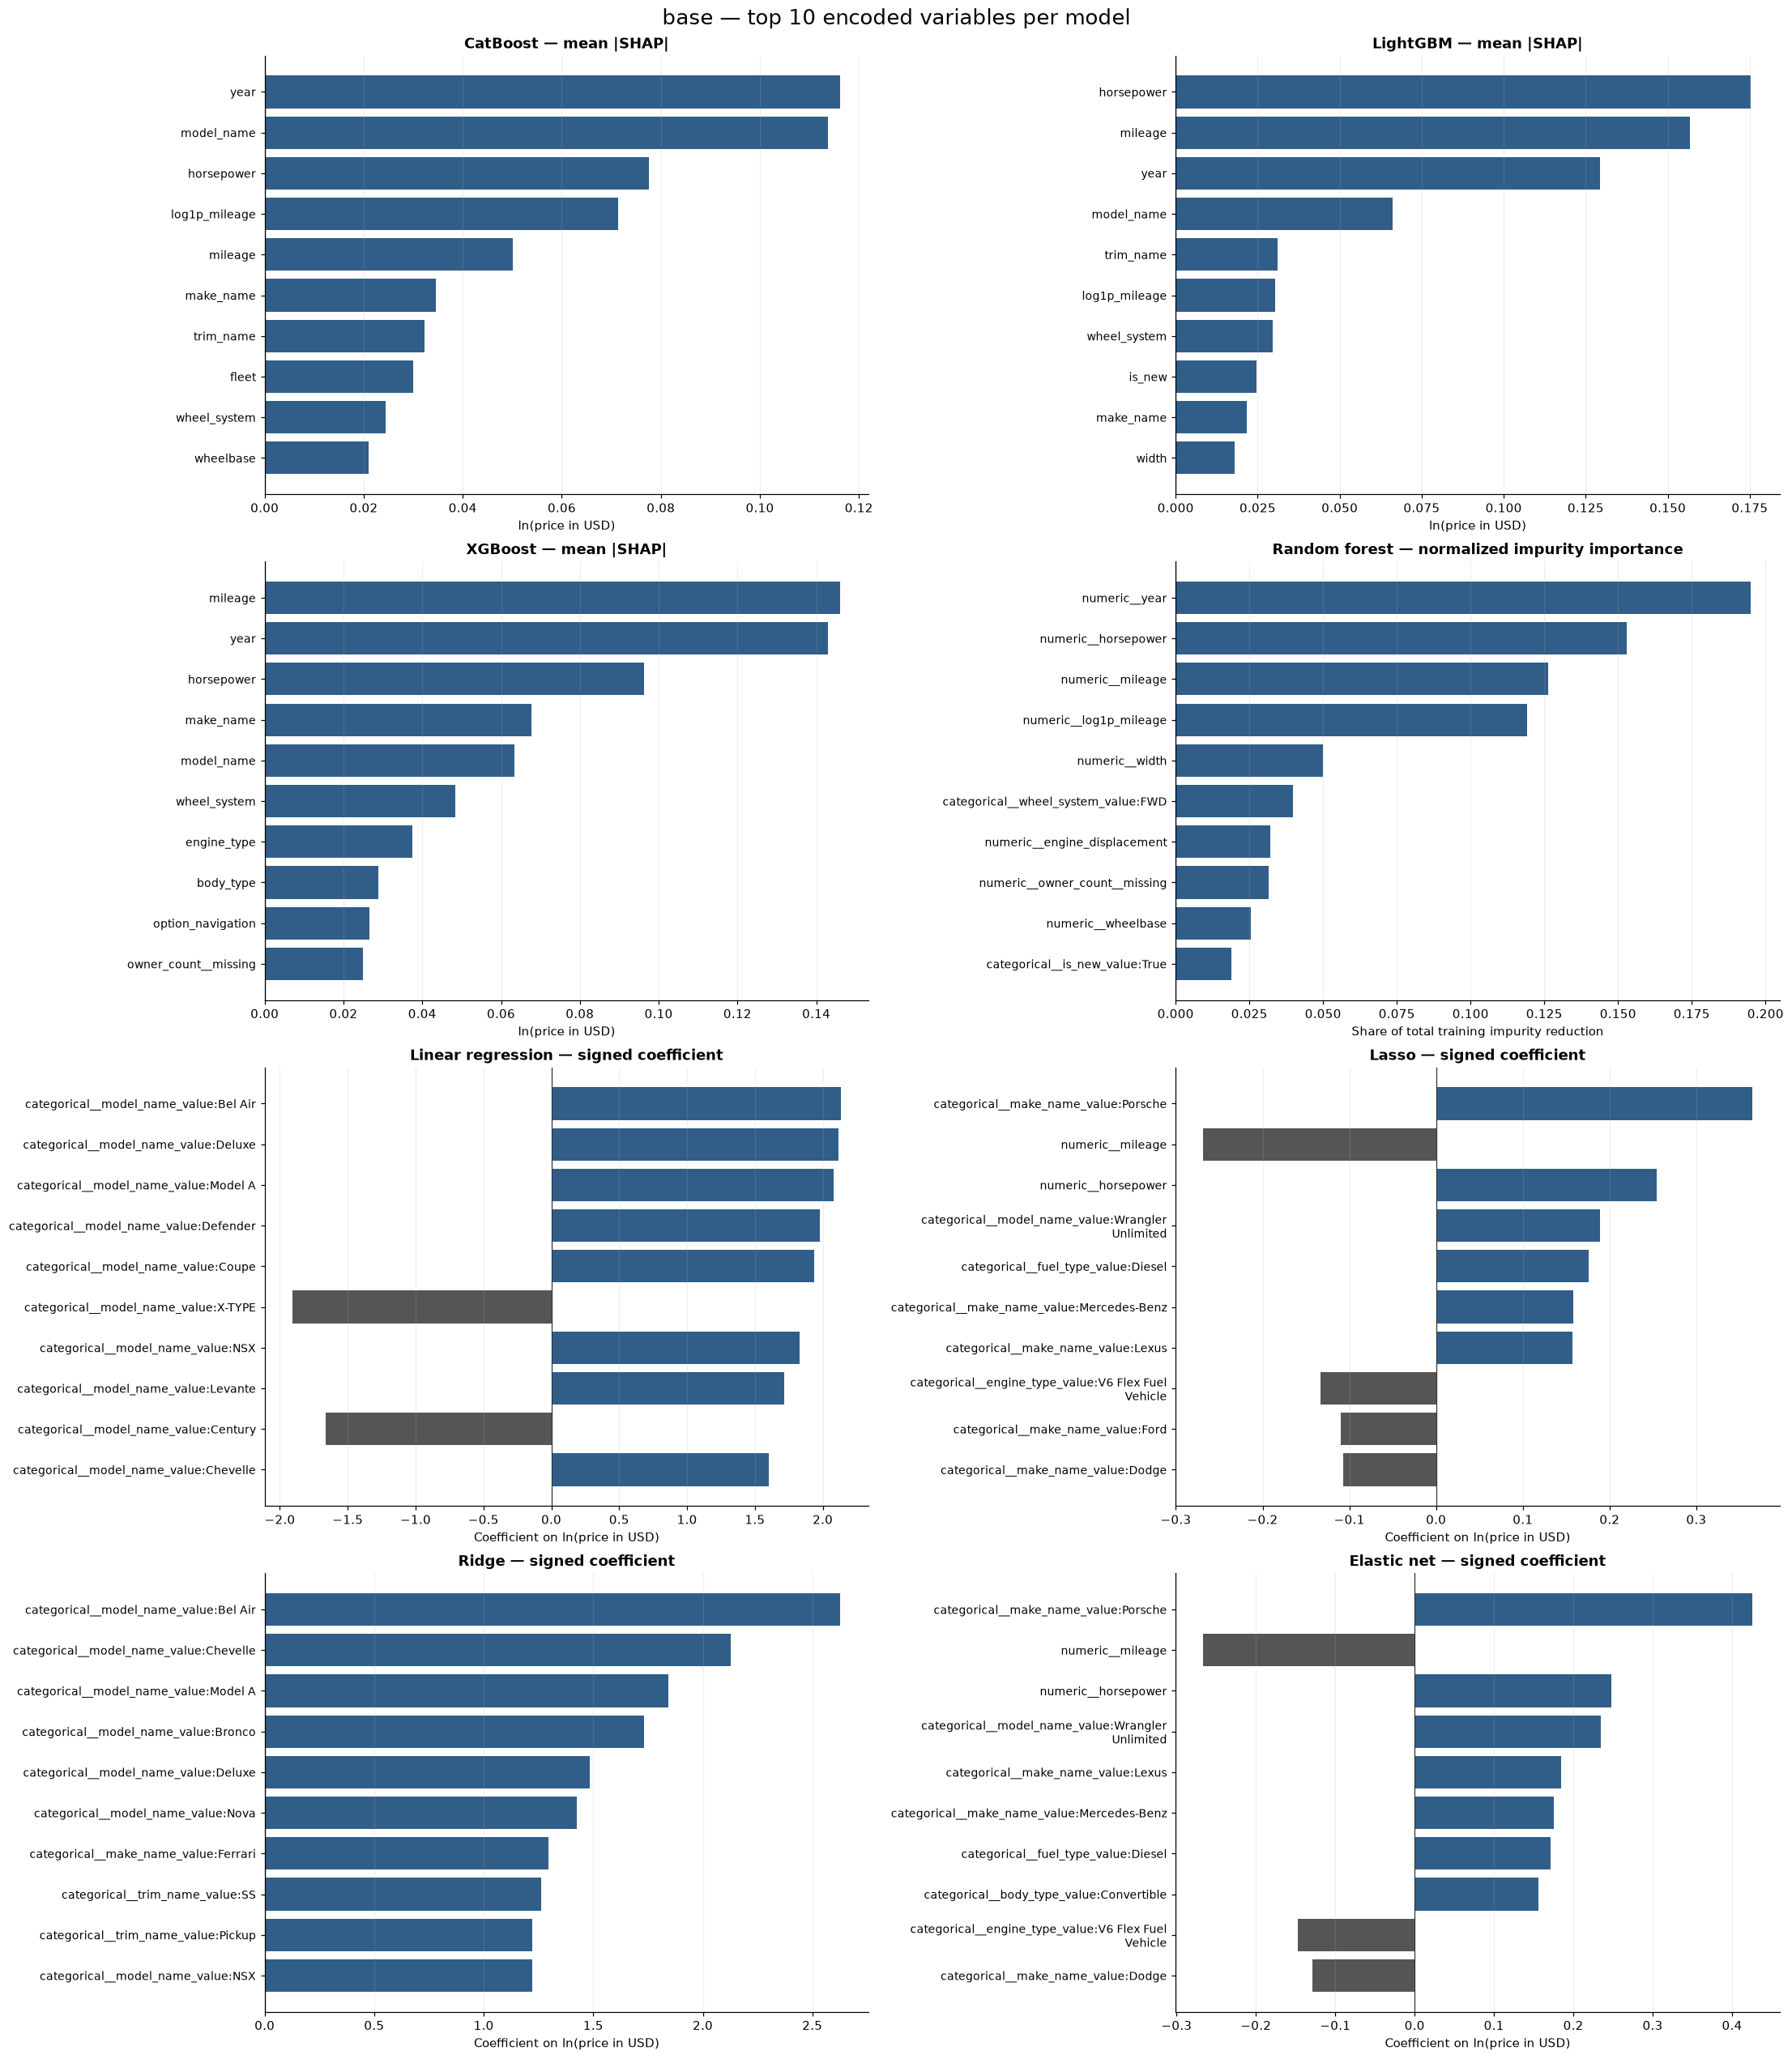

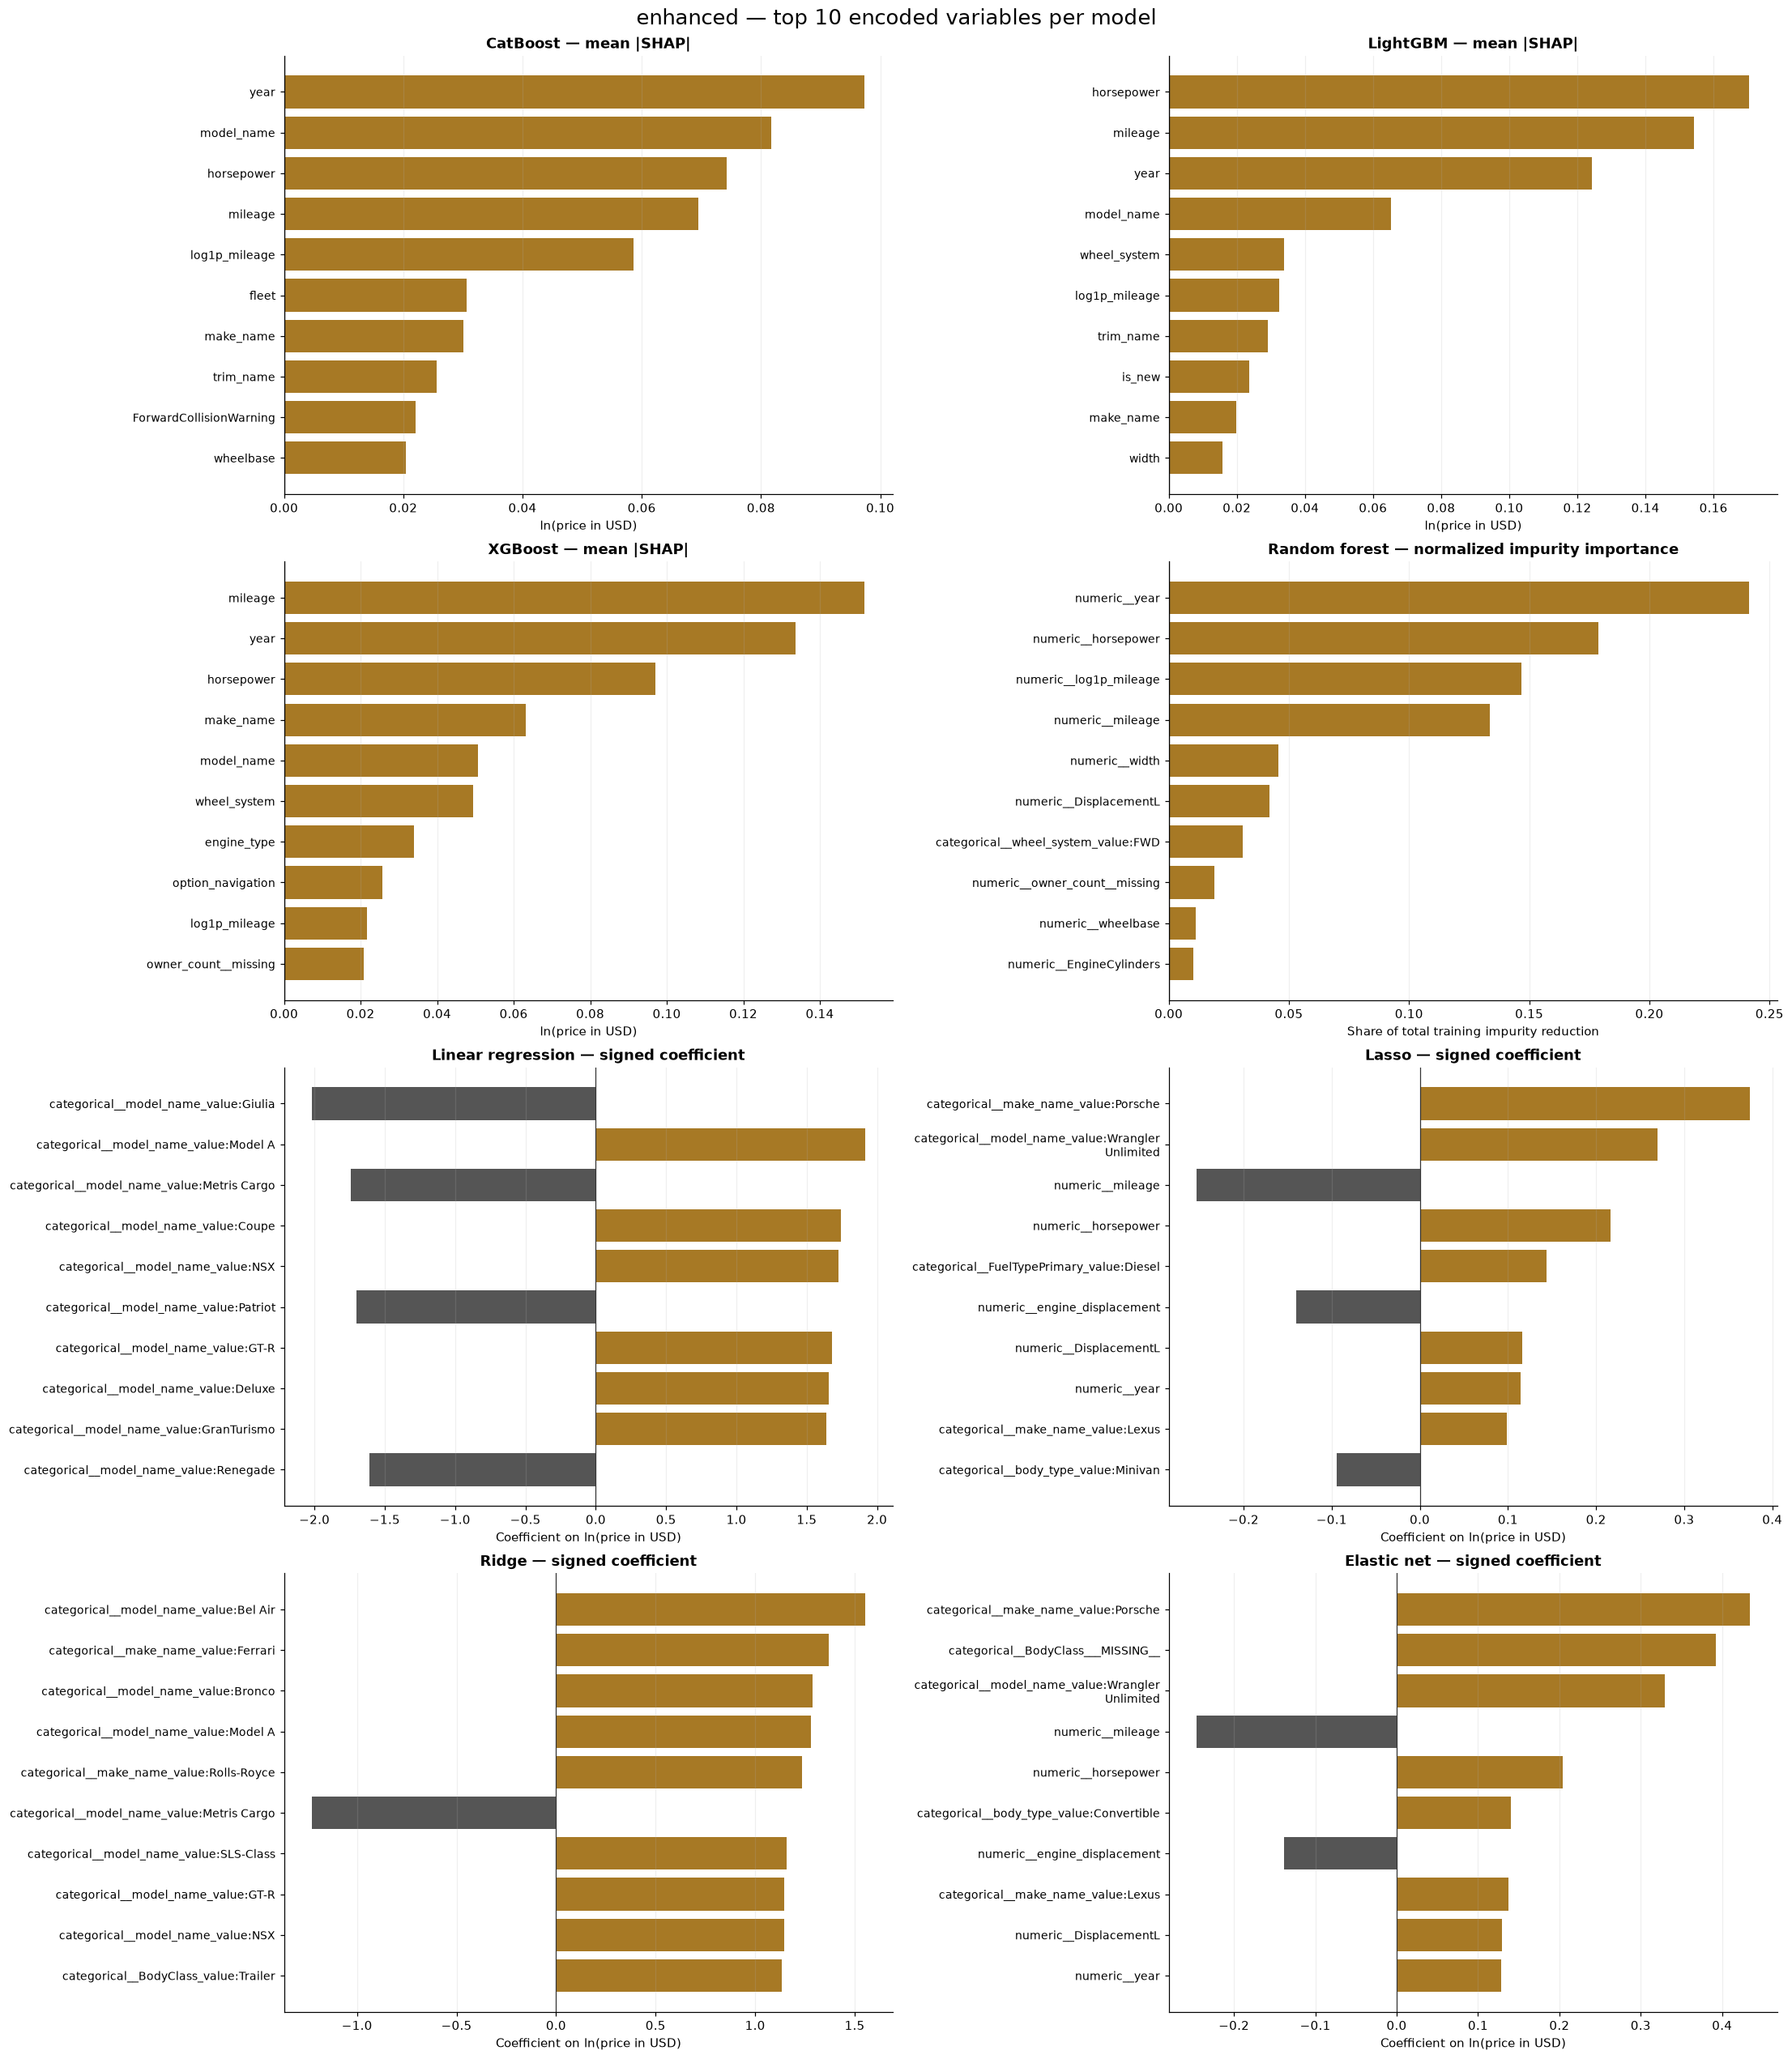

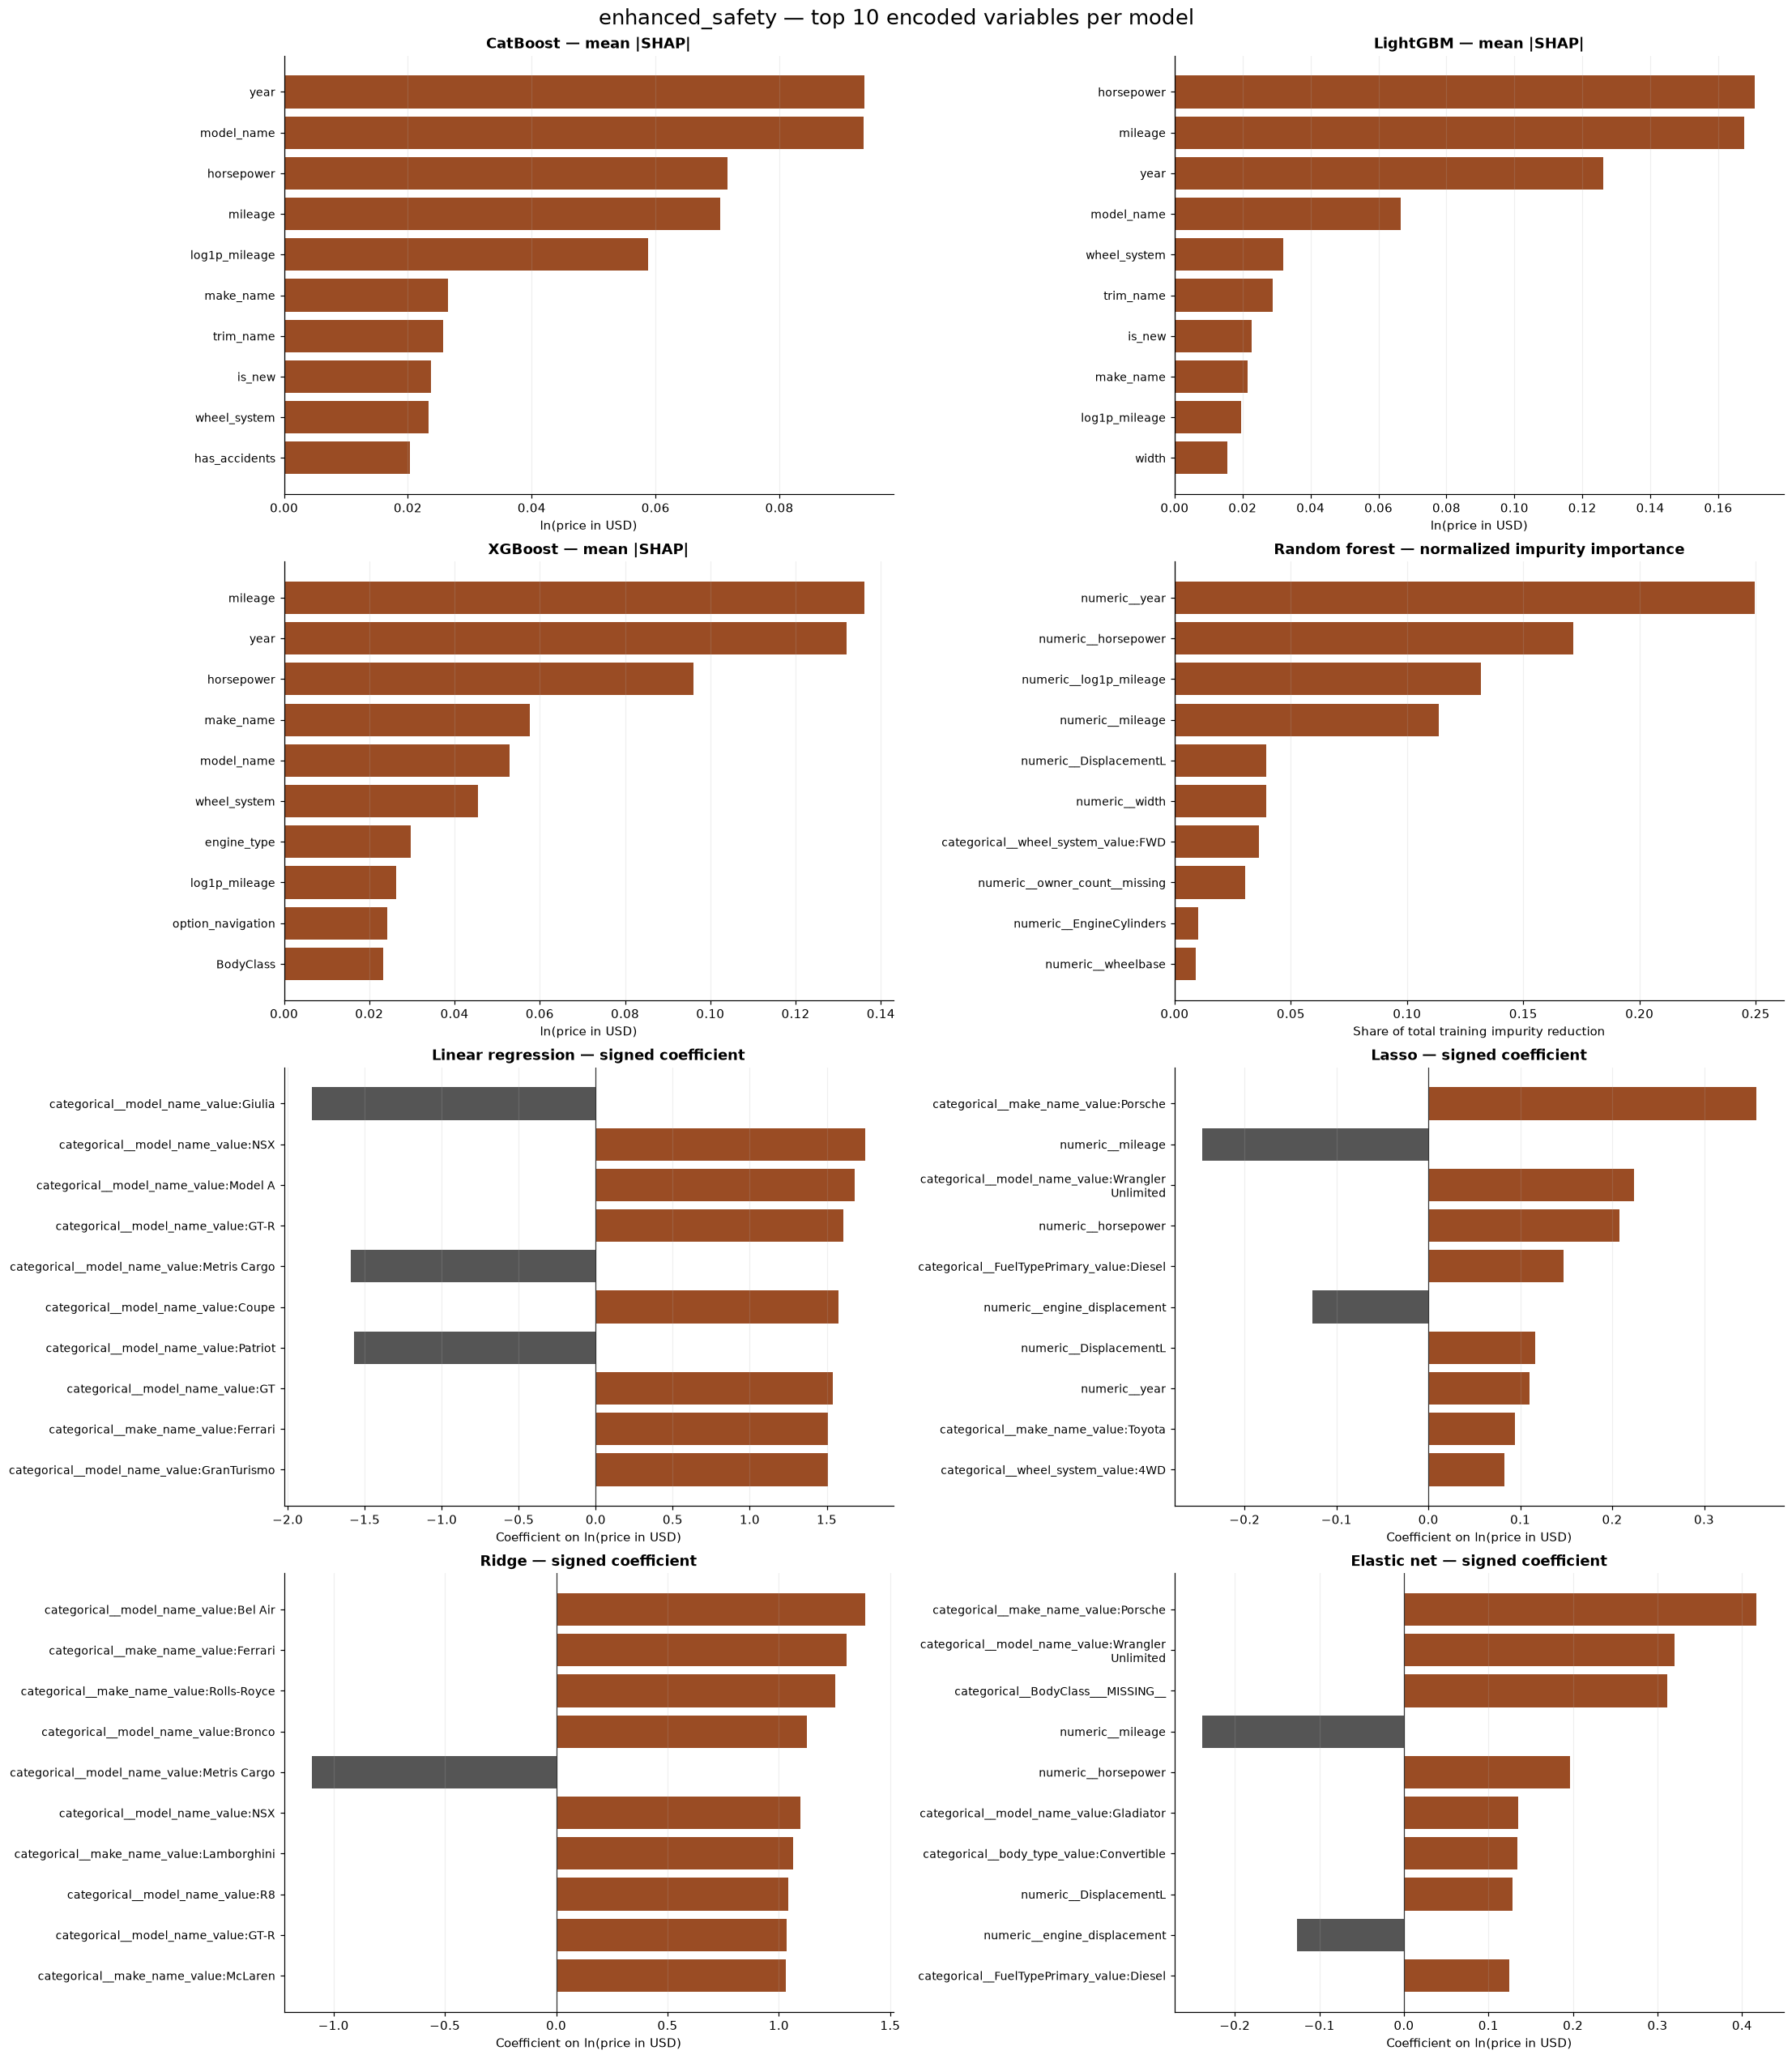

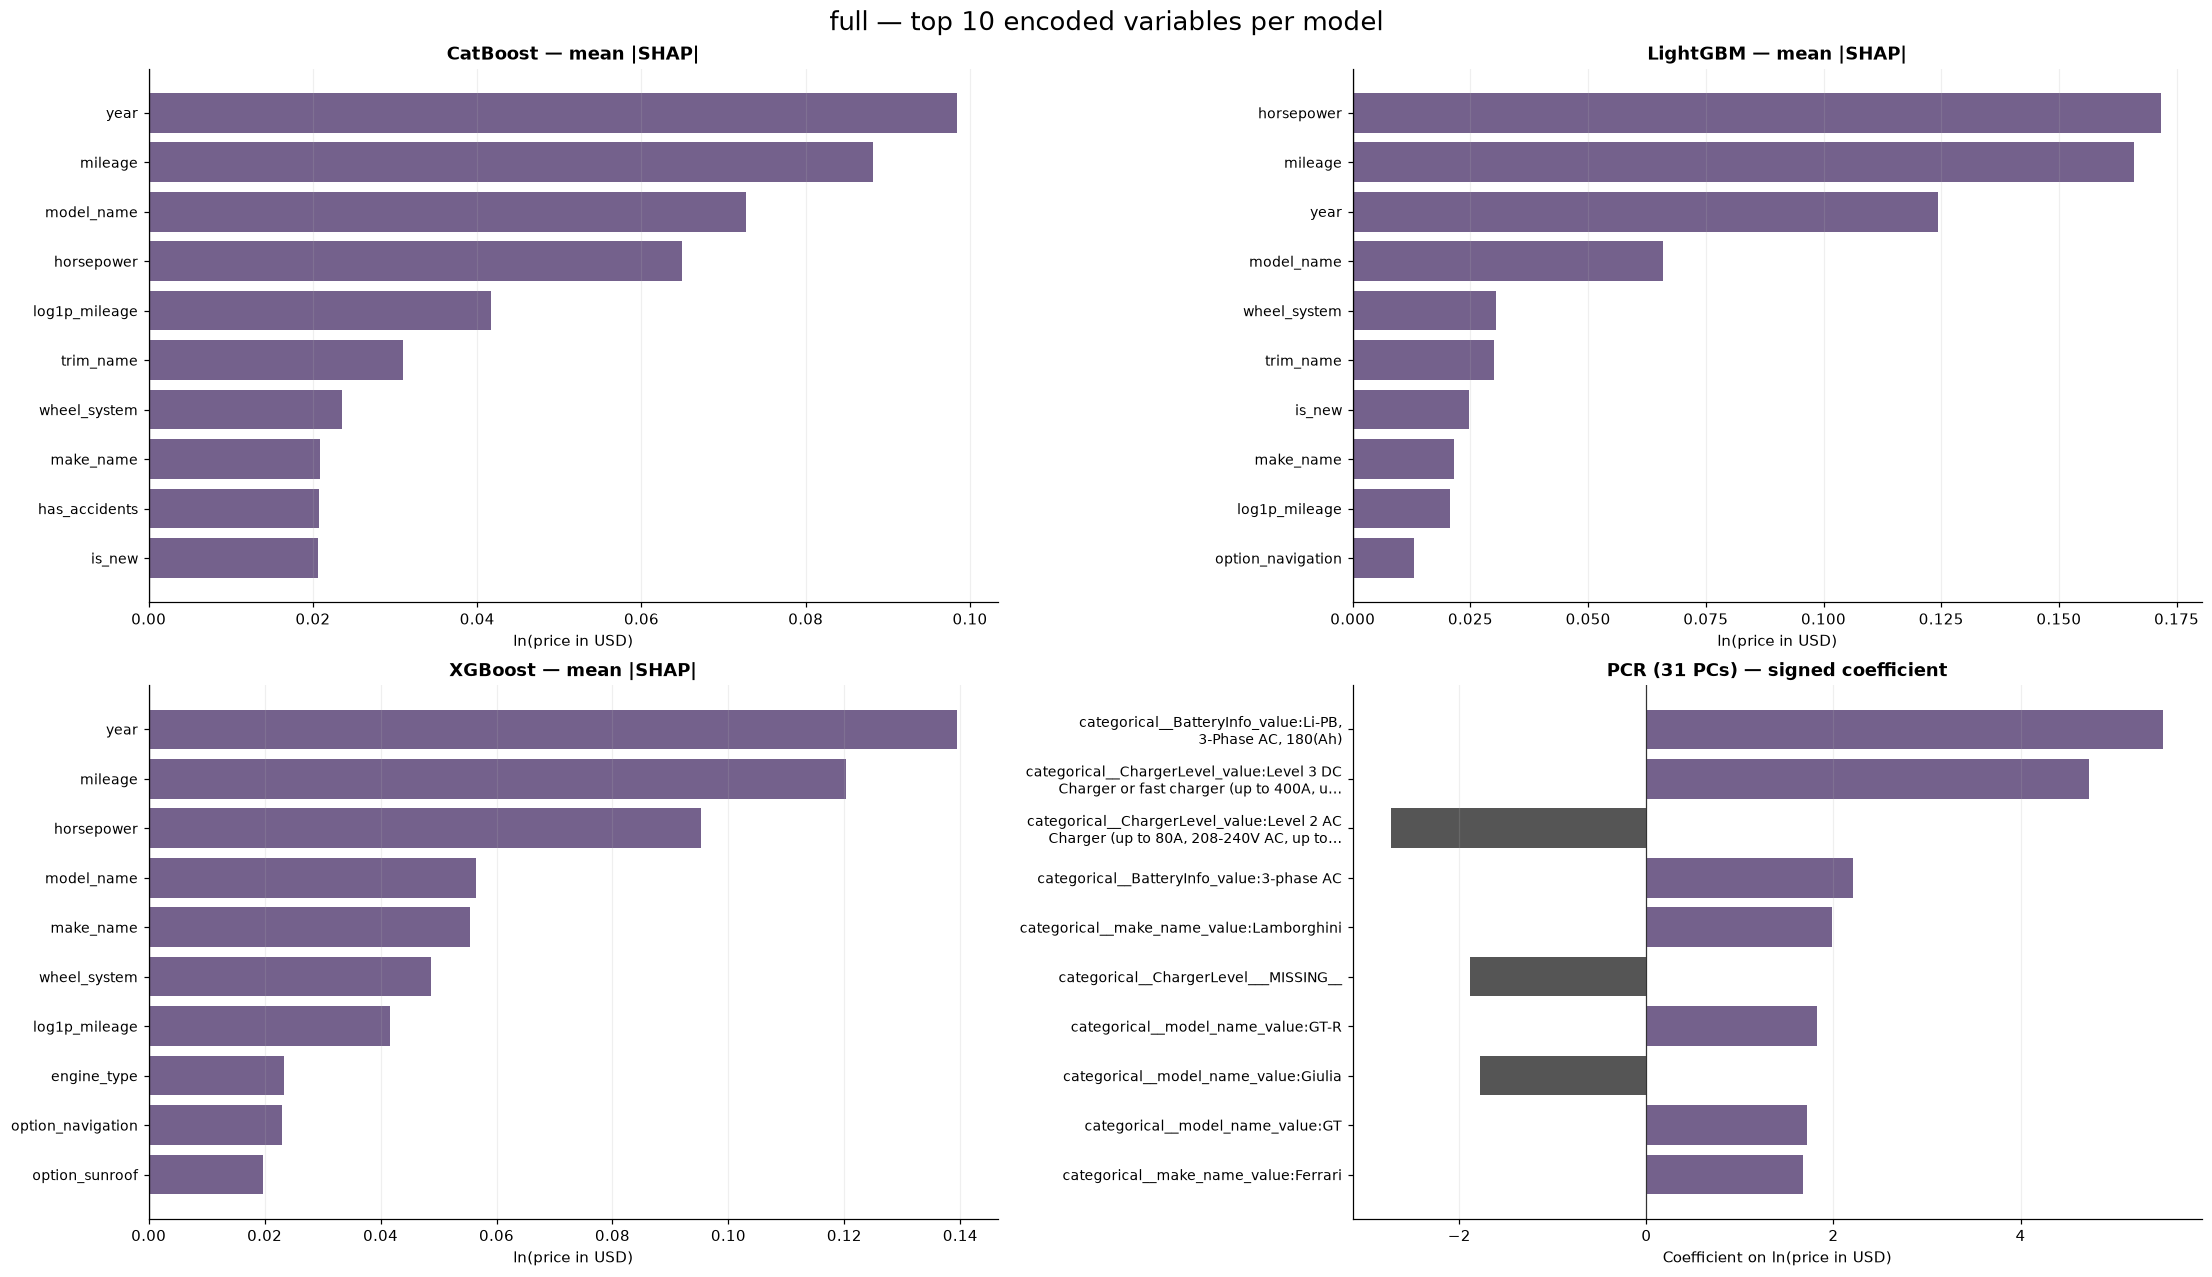

In [7]:
for variant in FEATURE_SETS:
    names = [name for name in MODELS if (variant, name) in selected]
    rows = max(1, (len(names) + 1) // 2)
    fig, axes = plt.subplots(rows, 2, figsize=(20, 5.75 * rows), constrained_layout=True)
    axes = np.asarray(axes).reshape(-1)
    for unused in axes[len(names):]:
        unused.set_axis_off()
    for ax, name in zip(axes, names):
        part = importance[(importance.feature_set == variant) & (importance.model == name)]
        method_label = ('normalized impurity importance' if name == 'random_forest' and FOREST_IMPORTANCE_METHOD == 'impurity'
                        else 'mean |SHAP|' if name in TREE_MODELS else 'signed coefficient')
        ax.set_title(f'{MODEL_LABELS[name]} — {method_label}')
        if part.empty:
            ax.text(.5, .5, 'Pending or unavailable; see status table', ha='center', transform=ax.transAxes)
            ax.set_axis_off()
            continue
        ordered = part.iloc[::-1]
        labels = [textwrap.fill(f if len(f) <= 84 else f[:81] + chr(8230), 44) for f in ordered.feature]
        colors = [COLORS[variant] if v >= 0 else '#555555' for v in ordered.value]
        ax.barh(range(len(ordered)), ordered.value, color=colors)
        ax.set_yticks(range(len(ordered)), labels, fontsize=9)
        ax.axvline(0, color='#333333', linewidth=.8)
        ax.set_xlabel('Share of total training impurity reduction' if name == 'random_forest' and FOREST_IMPORTANCE_METHOD == 'impurity'
                      else 'ln(price in USD)' if name in TREE_MODELS else 'Coefficient on ln(price in USD)')
        ax.grid(axis='x', alpha=.2)
    fig.suptitle(f'{variant} — top 10 encoded variables per model', fontsize=17)
    plt.show()

### Exact explanation values

In [8]:
for (variant, name), part in importance.groupby(['feature_set', 'model'], sort=False):
    table = part[['feature', 'value']].to_html(index=False, float_format=lambda v: f'{v:.6g}')
    display(HTML(f'<details><summary>{variant} / {MODEL_LABELS[name]} — top 10 values</summary>{table}</details>'))

feature,value
year,0.116166
model_name,0.113797
horsepower,0.0776391
log1p_mileage,0.0713189
mileage,0.0501148
make_name,0.0345545
trim_name,0.0322633
fleet,0.0300023
wheel_system,0.0243717
wheelbase,0.021001


feature,value
horsepower,0.175366
mileage,0.156718
year,0.129389
model_name,0.0662382
trim_name,0.0310423
log1p_mileage,0.0303627
wheel_system,0.0295402
is_new,0.024662
make_name,0.0217976
width,0.0180012


feature,value
mileage,0.146003
year,0.143037
horsepower,0.0963804
make_name,0.067717
model_name,0.0633182
wheel_system,0.0484671
engine_type,0.0375417
body_type,0.0289264
option_navigation,0.0265297
owner_count__missing,0.024963


feature,value
numeric__year,0.195068
numeric__horsepower,0.153003
numeric__mileage,0.126299
numeric__log1p_mileage,0.119034
numeric__width,0.0498631
categorical__wheel_system_value:FWD,0.0396463
numeric__engine_displacement,0.0321012
numeric__owner_count__missing,0.0315299
numeric__wheelbase,0.0254761
categorical__is_new_value:True,0.0188259


feature,value
categorical__model_name_value:Bel Air,2.13614
categorical__model_name_value:Deluxe,2.11604
categorical__model_name_value:Model A,2.08199
categorical__model_name_value:Defender,1.98038
categorical__model_name_value:Coupe,1.93887
categorical__model_name_value:X-TYPE,-1.90978
categorical__model_name_value:NSX,1.82664
categorical__model_name_value:Levante,1.71285
categorical__model_name_value:Century,-1.65975
categorical__model_name_value:Chevelle,1.60477


...

feature,value
categorical__make_name_value:Porsche,0.416543
categorical__model_name_value:Wrangler Unlimited,0.320223
categorical__BodyClass___MISSING__,0.311876
numeric__mileage,-0.23845
numeric__horsepower,0.196416
categorical__model_name_value:Gladiator,0.135056
categorical__body_type_value:Convertible,0.134449
numeric__DisplacementL,0.128072
numeric__engine_displacement,-0.126052
categorical__FuelTypePrimary_value:Diesel,0.124572


feature,value
year,0.098459
mileage,0.0882353
model_name,0.0727571
horsepower,0.0648819
log1p_mileage,0.041679
trim_name,0.0309986
wheel_system,0.0235795
make_name,0.0208361
has_accidents,0.0207353
is_new,0.0206096


feature,value
horsepower,0.171771
mileage,0.165991
year,0.124379
model_name,0.0658093
wheel_system,0.0304598
trim_name,0.0299141
is_new,0.0246526
make_name,0.0214065
log1p_mileage,0.0205971
option_navigation,0.0130643


feature,value
year,0.139488
mileage,0.120249
horsepower,0.095313
model_name,0.0564222
make_name,0.0554243
wheel_system,0.0486794
log1p_mileage,0.041618
engine_type,0.0233255
option_navigation,0.0230038
option_sunroof,0.0196442


feature,value
"categorical__BatteryInfo_value:Li-PB, 3-Phase AC, 180(Ah)",5.52589
"categorical__ChargerLevel_value:Level 3 DC Charger or fast charger (up to 400A, up to 600V DC, up to 240KW)",4.73554
"categorical__ChargerLevel_value:Level 2 AC Charger (up to 80A, 208-240V AC, up to 20kW from single- or three-phase AC) cables permanently fixed to charging station.",-2.72624
categorical__BatteryInfo_value:3-phase AC,2.20574
categorical__make_name_value:Lamborghini,1.98015
categorical__ChargerLevel___MISSING__,-1.88297
categorical__model_name_value:GT-R,1.82011
categorical__model_name_value:Giulia,-1.77759
categorical__model_name_value:GT,1.72163
categorical__make_name_value:Ferrari,1.67447


## 5. Performance across makes

Prices describe held-out listings, not the whole market. Low support means fewer than 100 listings or five family blocks. Narrow price ranges can destabilize R². WAPE provides relative-error context; no per-make significance is established.

,Make,rows,family_blocks,mean_actual_price,median_actual_price,support_status
0,MCLAREN,3,1,"1,174,593.33","1,075,000.00",low_support
1,ROLLS-ROYCE,64,10,"289,936.52","324,975.00",low_support
2,FERRARI,214,29,"252,334.01","205,000.00",supported
3,ASTON MARTIN,196,13,"183,721.03","182,014.00",supported
4,LAMBORGHINI,37,7,"138,811.76","125,583.00",low_support
5,BENTLEY,140,18,"116,465.61","74,800.00",supported
6,PORSCHE,"2,912",26,"87,597.10","83,920.00",supported
7,KARMA,2,1,"83,992.50","83,992.50",low_support
8,MASERATI,640,13,"66,176.72","53,650.00",supported
9,FONTAINE TRAILER CO.,1,1,"62,500.00","62,500.00",low_support


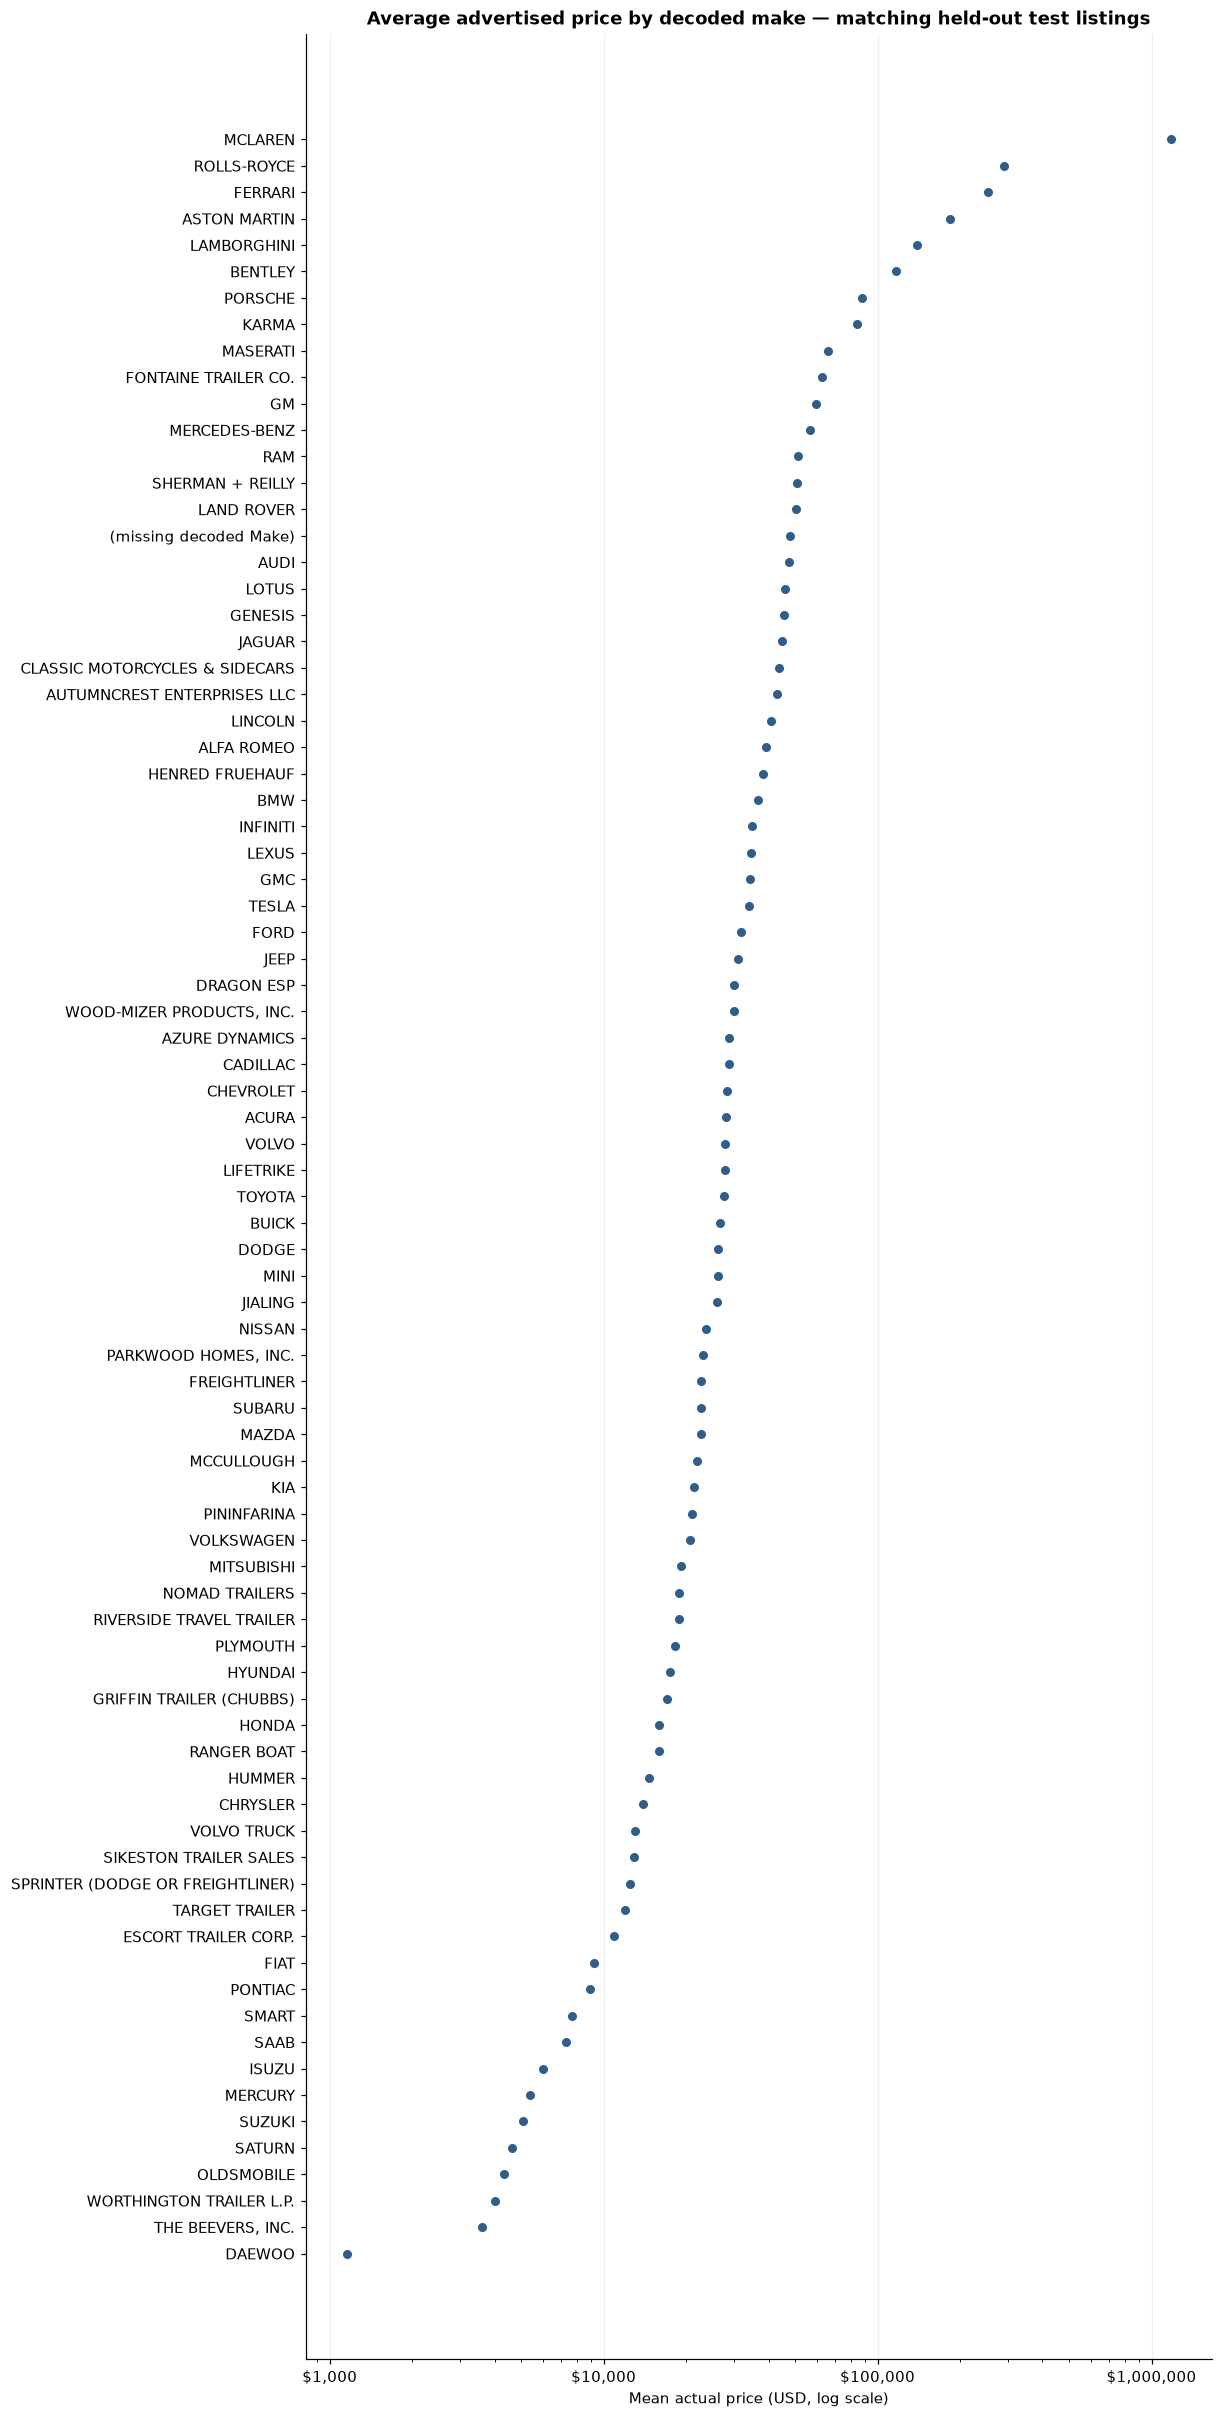

In [9]:
price_by_make = make_metrics[['Make', 'rows', 'family_blocks', 'mean_actual_price', 'median_actual_price', 'support_status']].drop_duplicates()
assert not price_by_make.Make.duplicated().any(), 'Make populations differ across checkpoints'
price_by_make = price_by_make.sort_values('mean_actual_price', ascending=False).reset_index(drop=True)
display(formatted(price_by_make))
fig, ax = plt.subplots(figsize=(11, max(8, len(price_by_make) * .27)), constrained_layout=True)
ordered = price_by_make.iloc[::-1]
ax.scatter(ordered.mean_actual_price, range(len(ordered)), color='#315E88', s=24)
ax.set_yticks(range(len(ordered)), ordered.Make)
ax.set_xscale('log')
ax.set_title('Average advertised price by decoded make — matching held-out test listings')
ax.set_xlabel('Mean actual price (USD, log scale)')
ax.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.grid(axis='x', alpha=.2)
plt.show()

### All-make comparison

Heatmaps share a logarithmic color scale; labels remain USD MAE. Missing cells are pending. Full metrics are in `make_metrics.csv`.

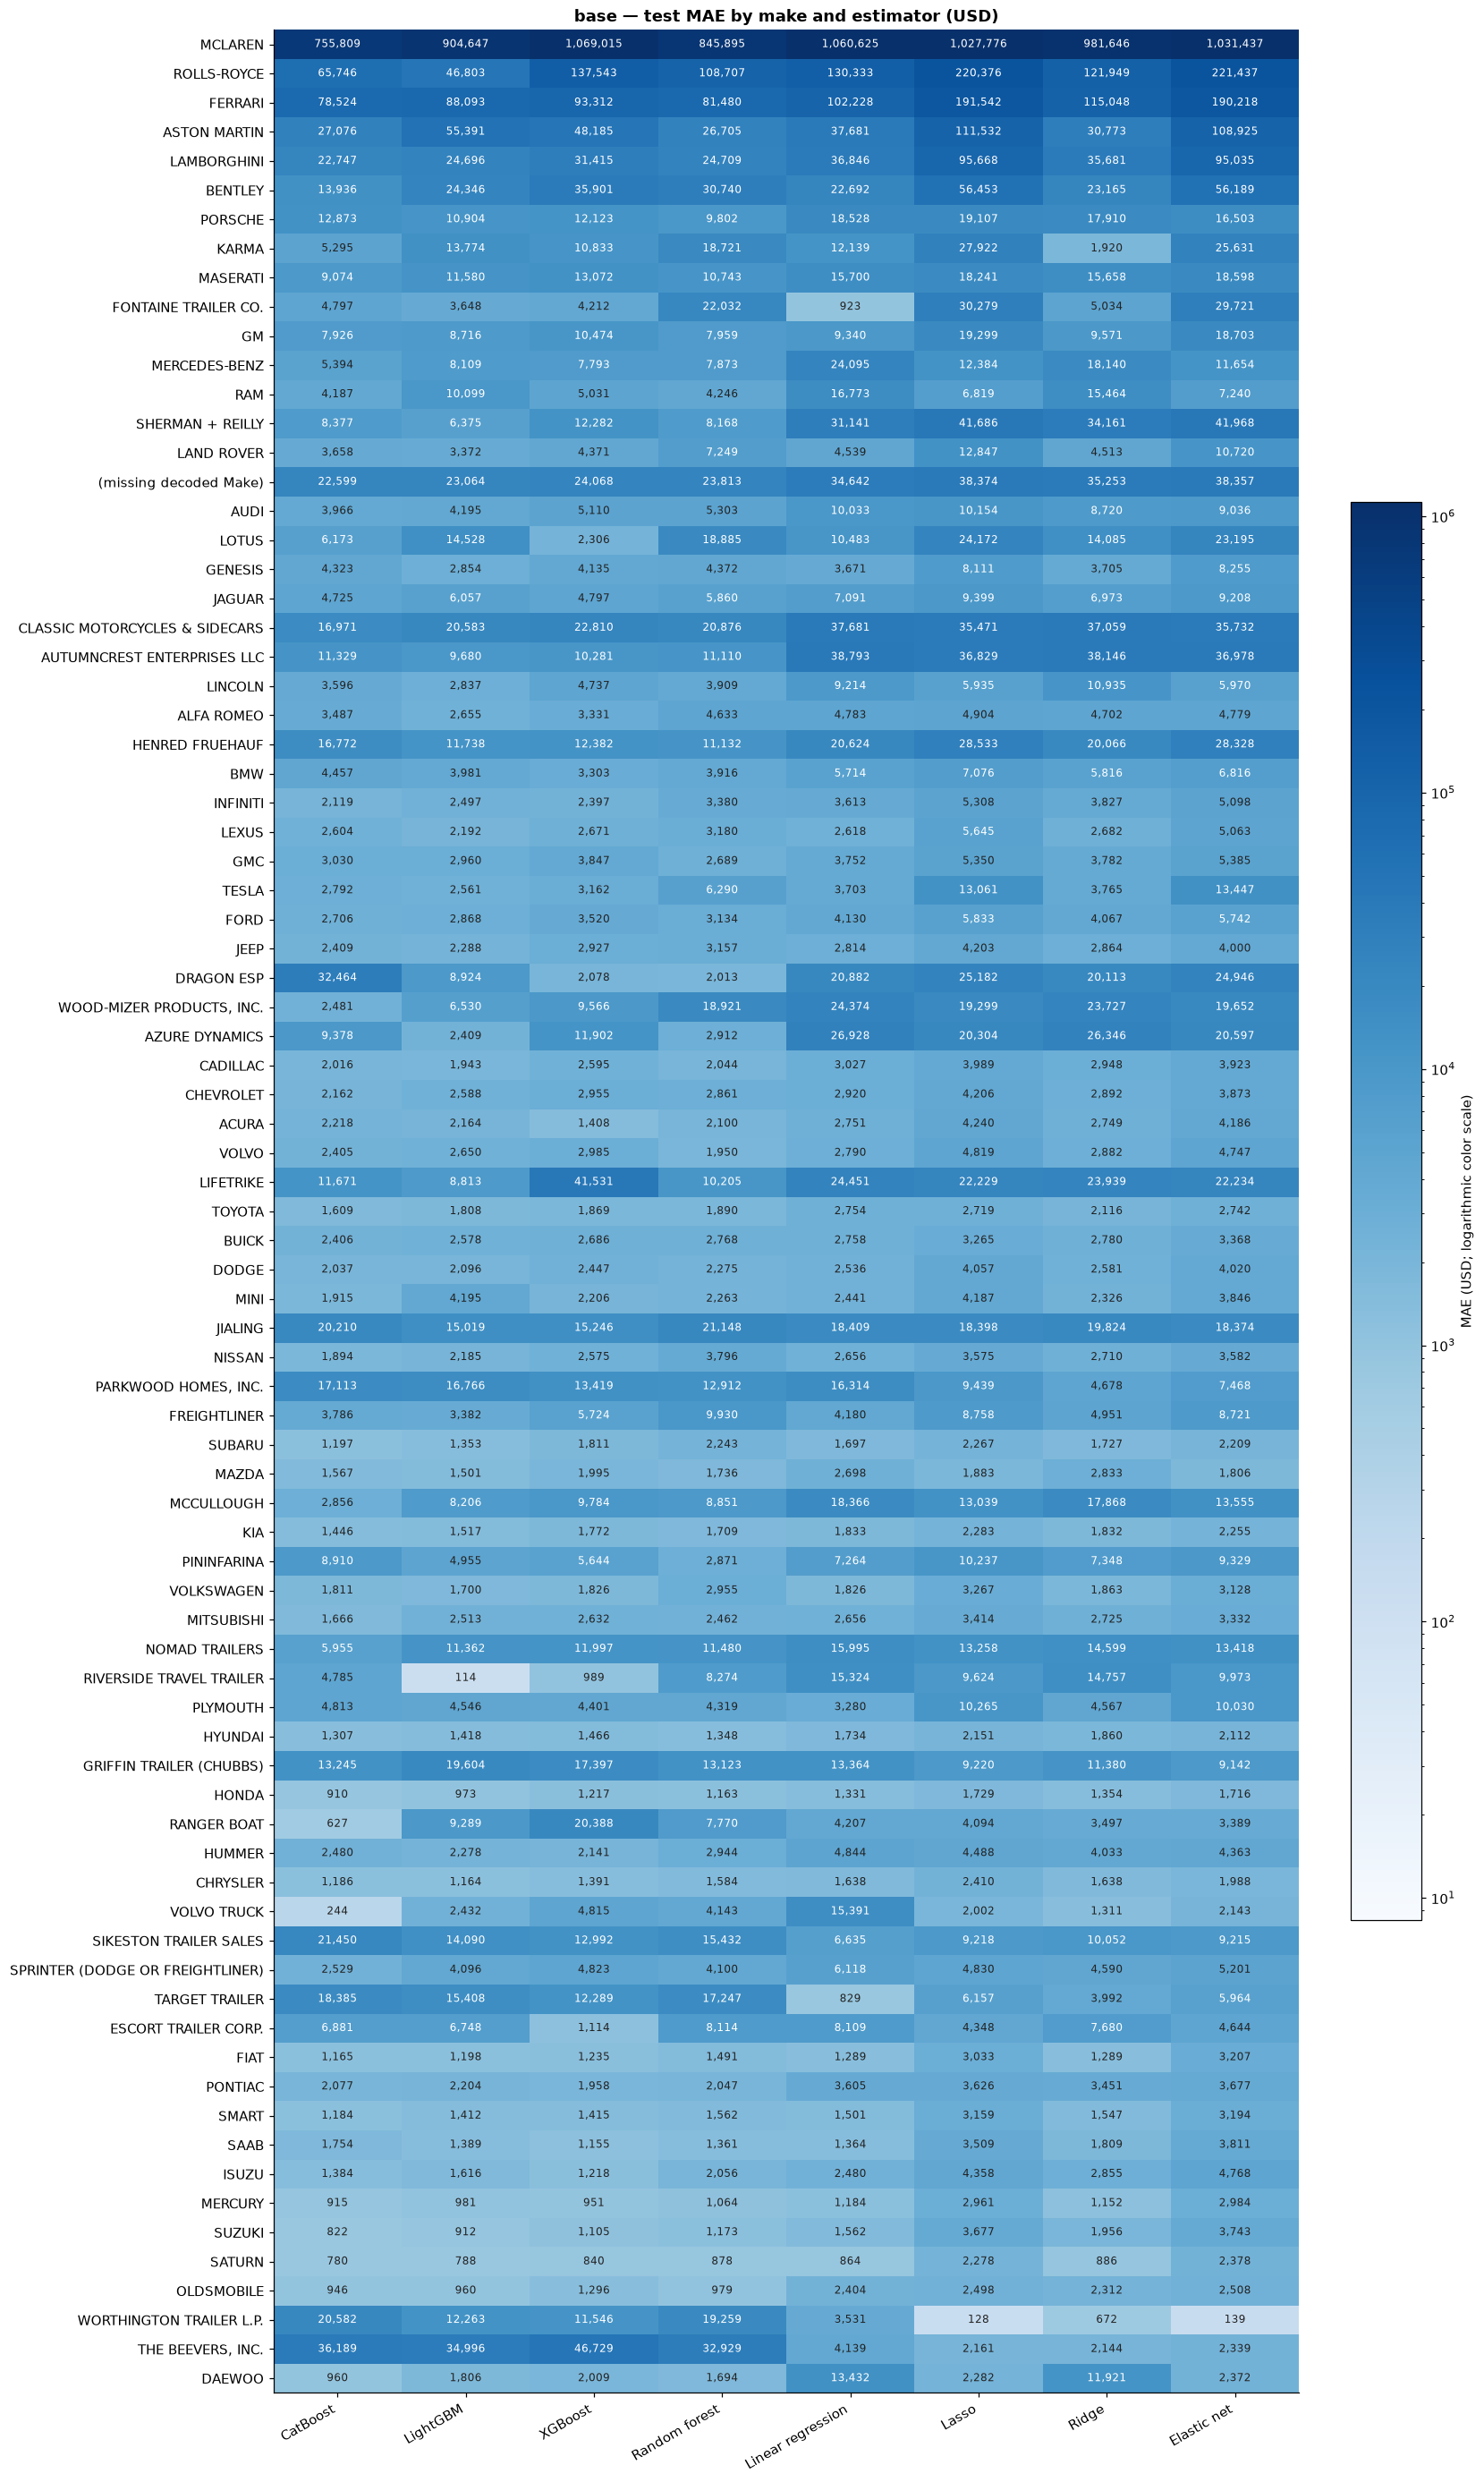

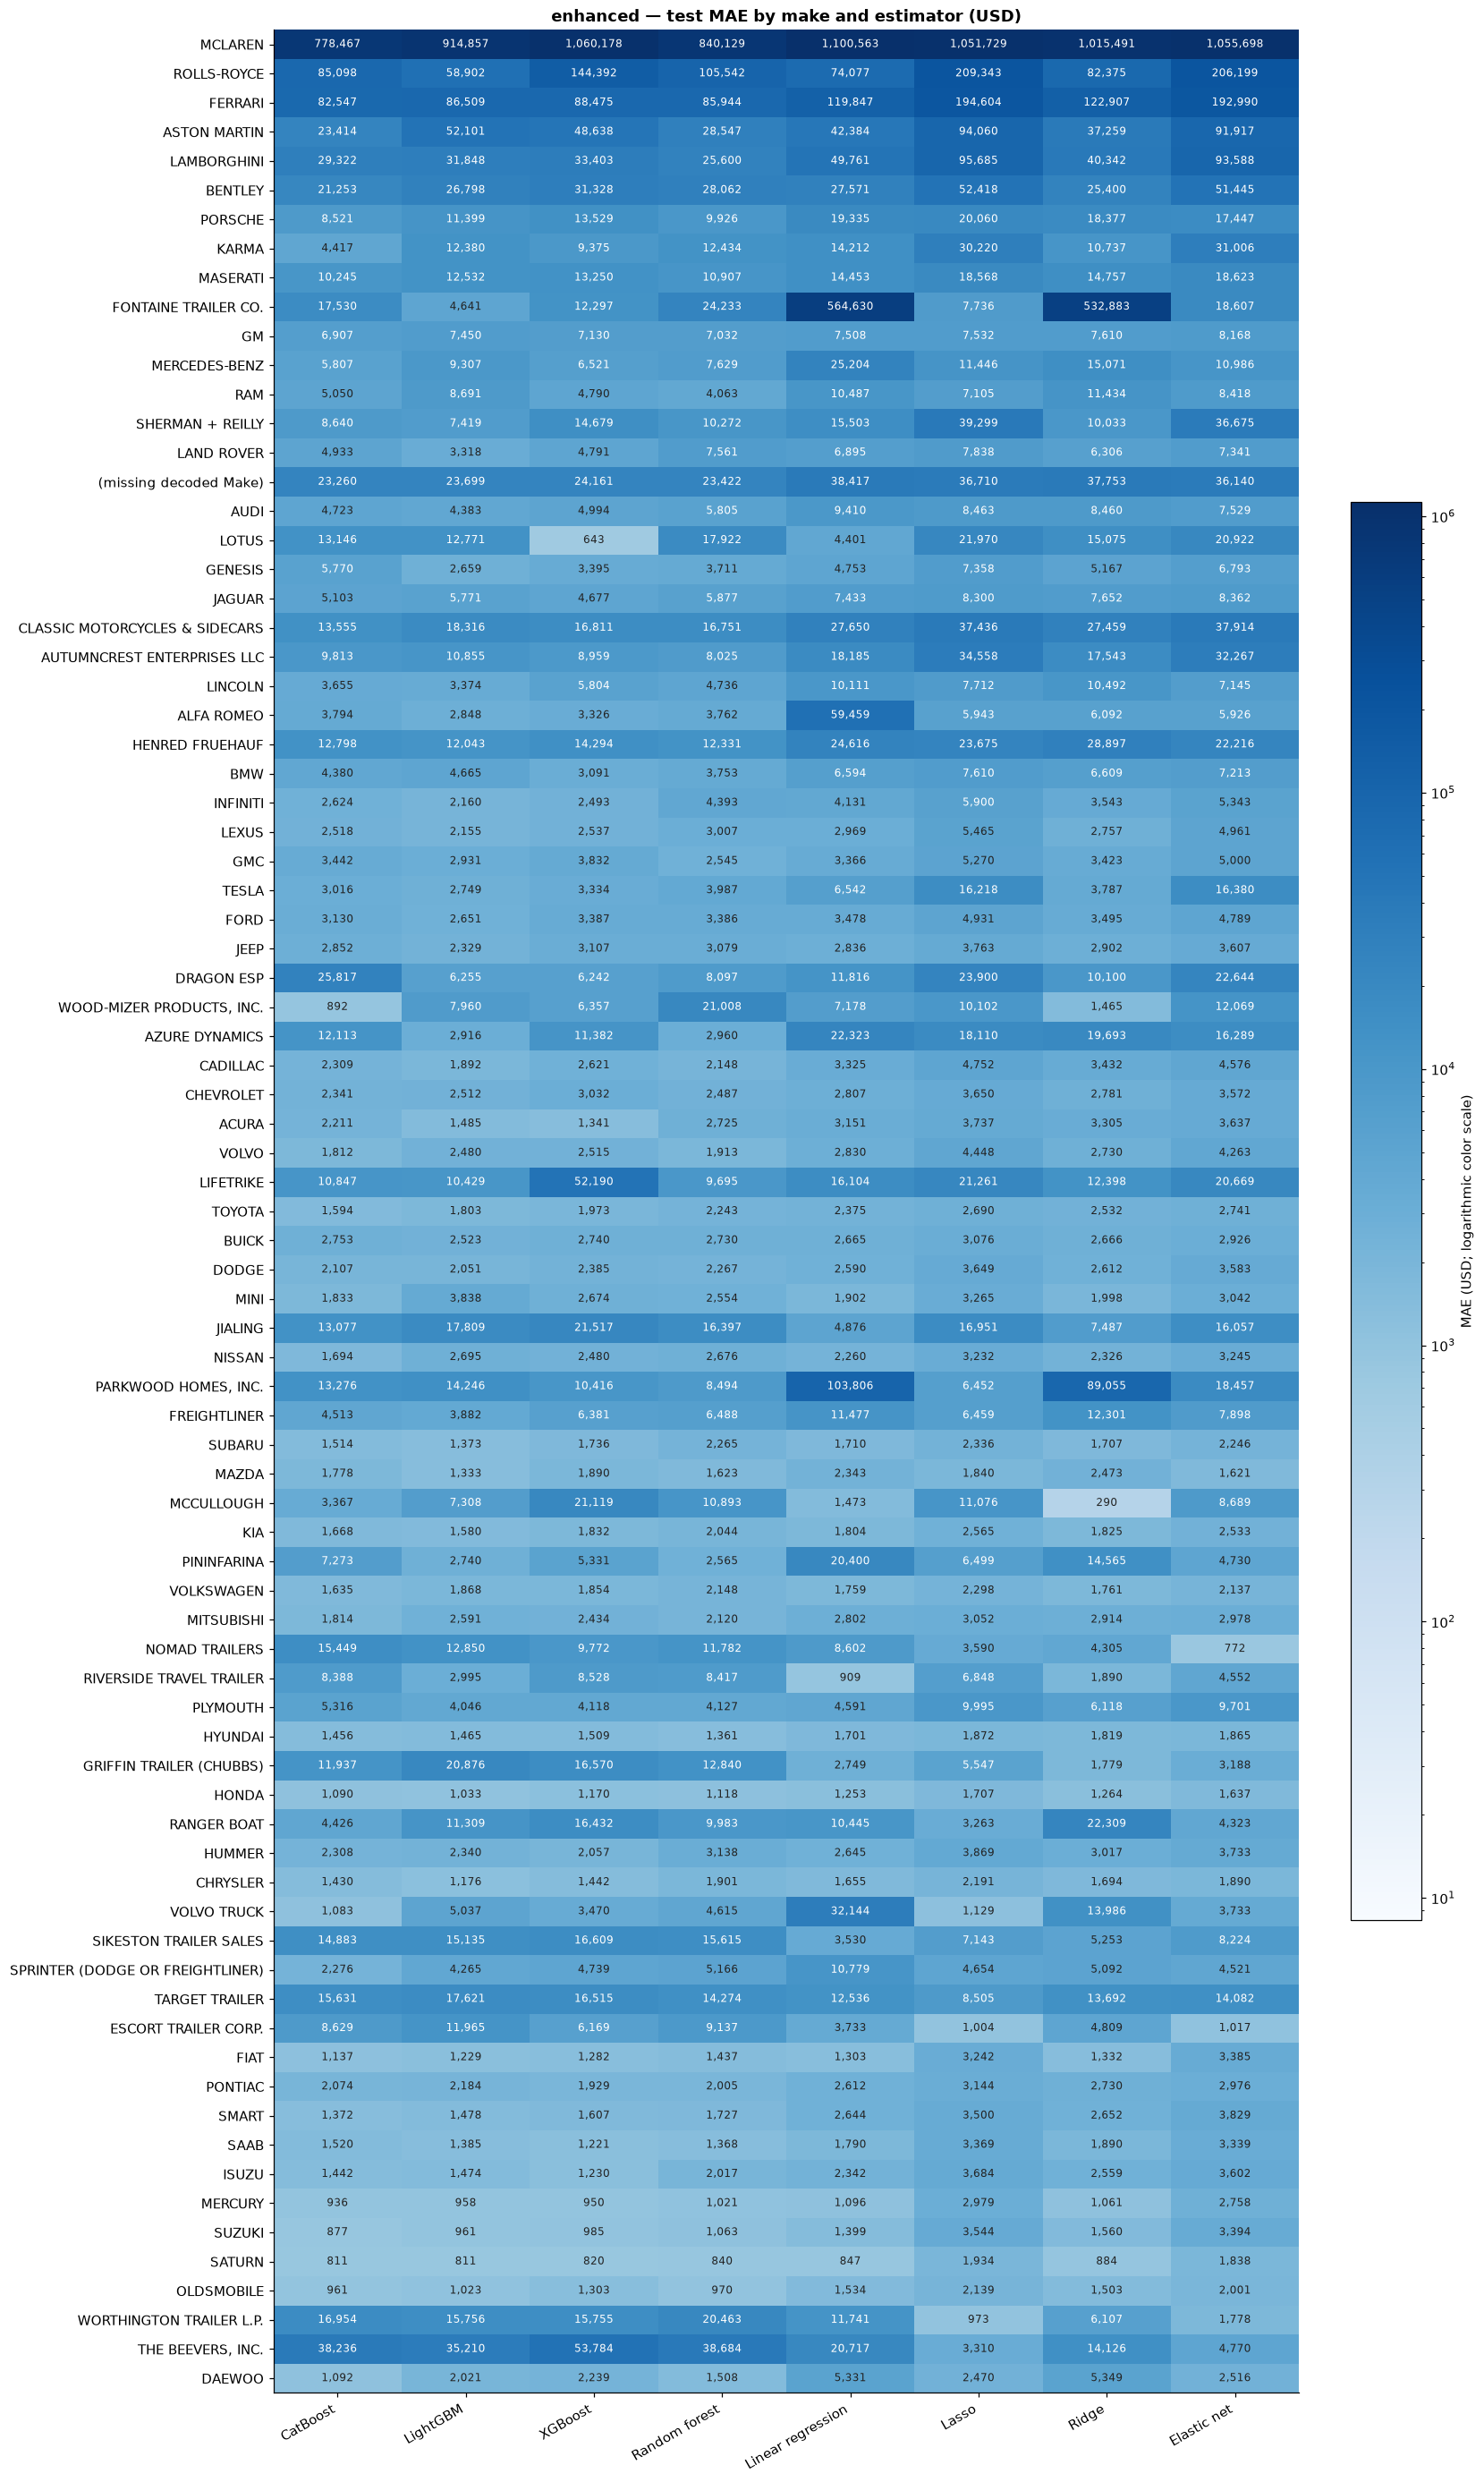

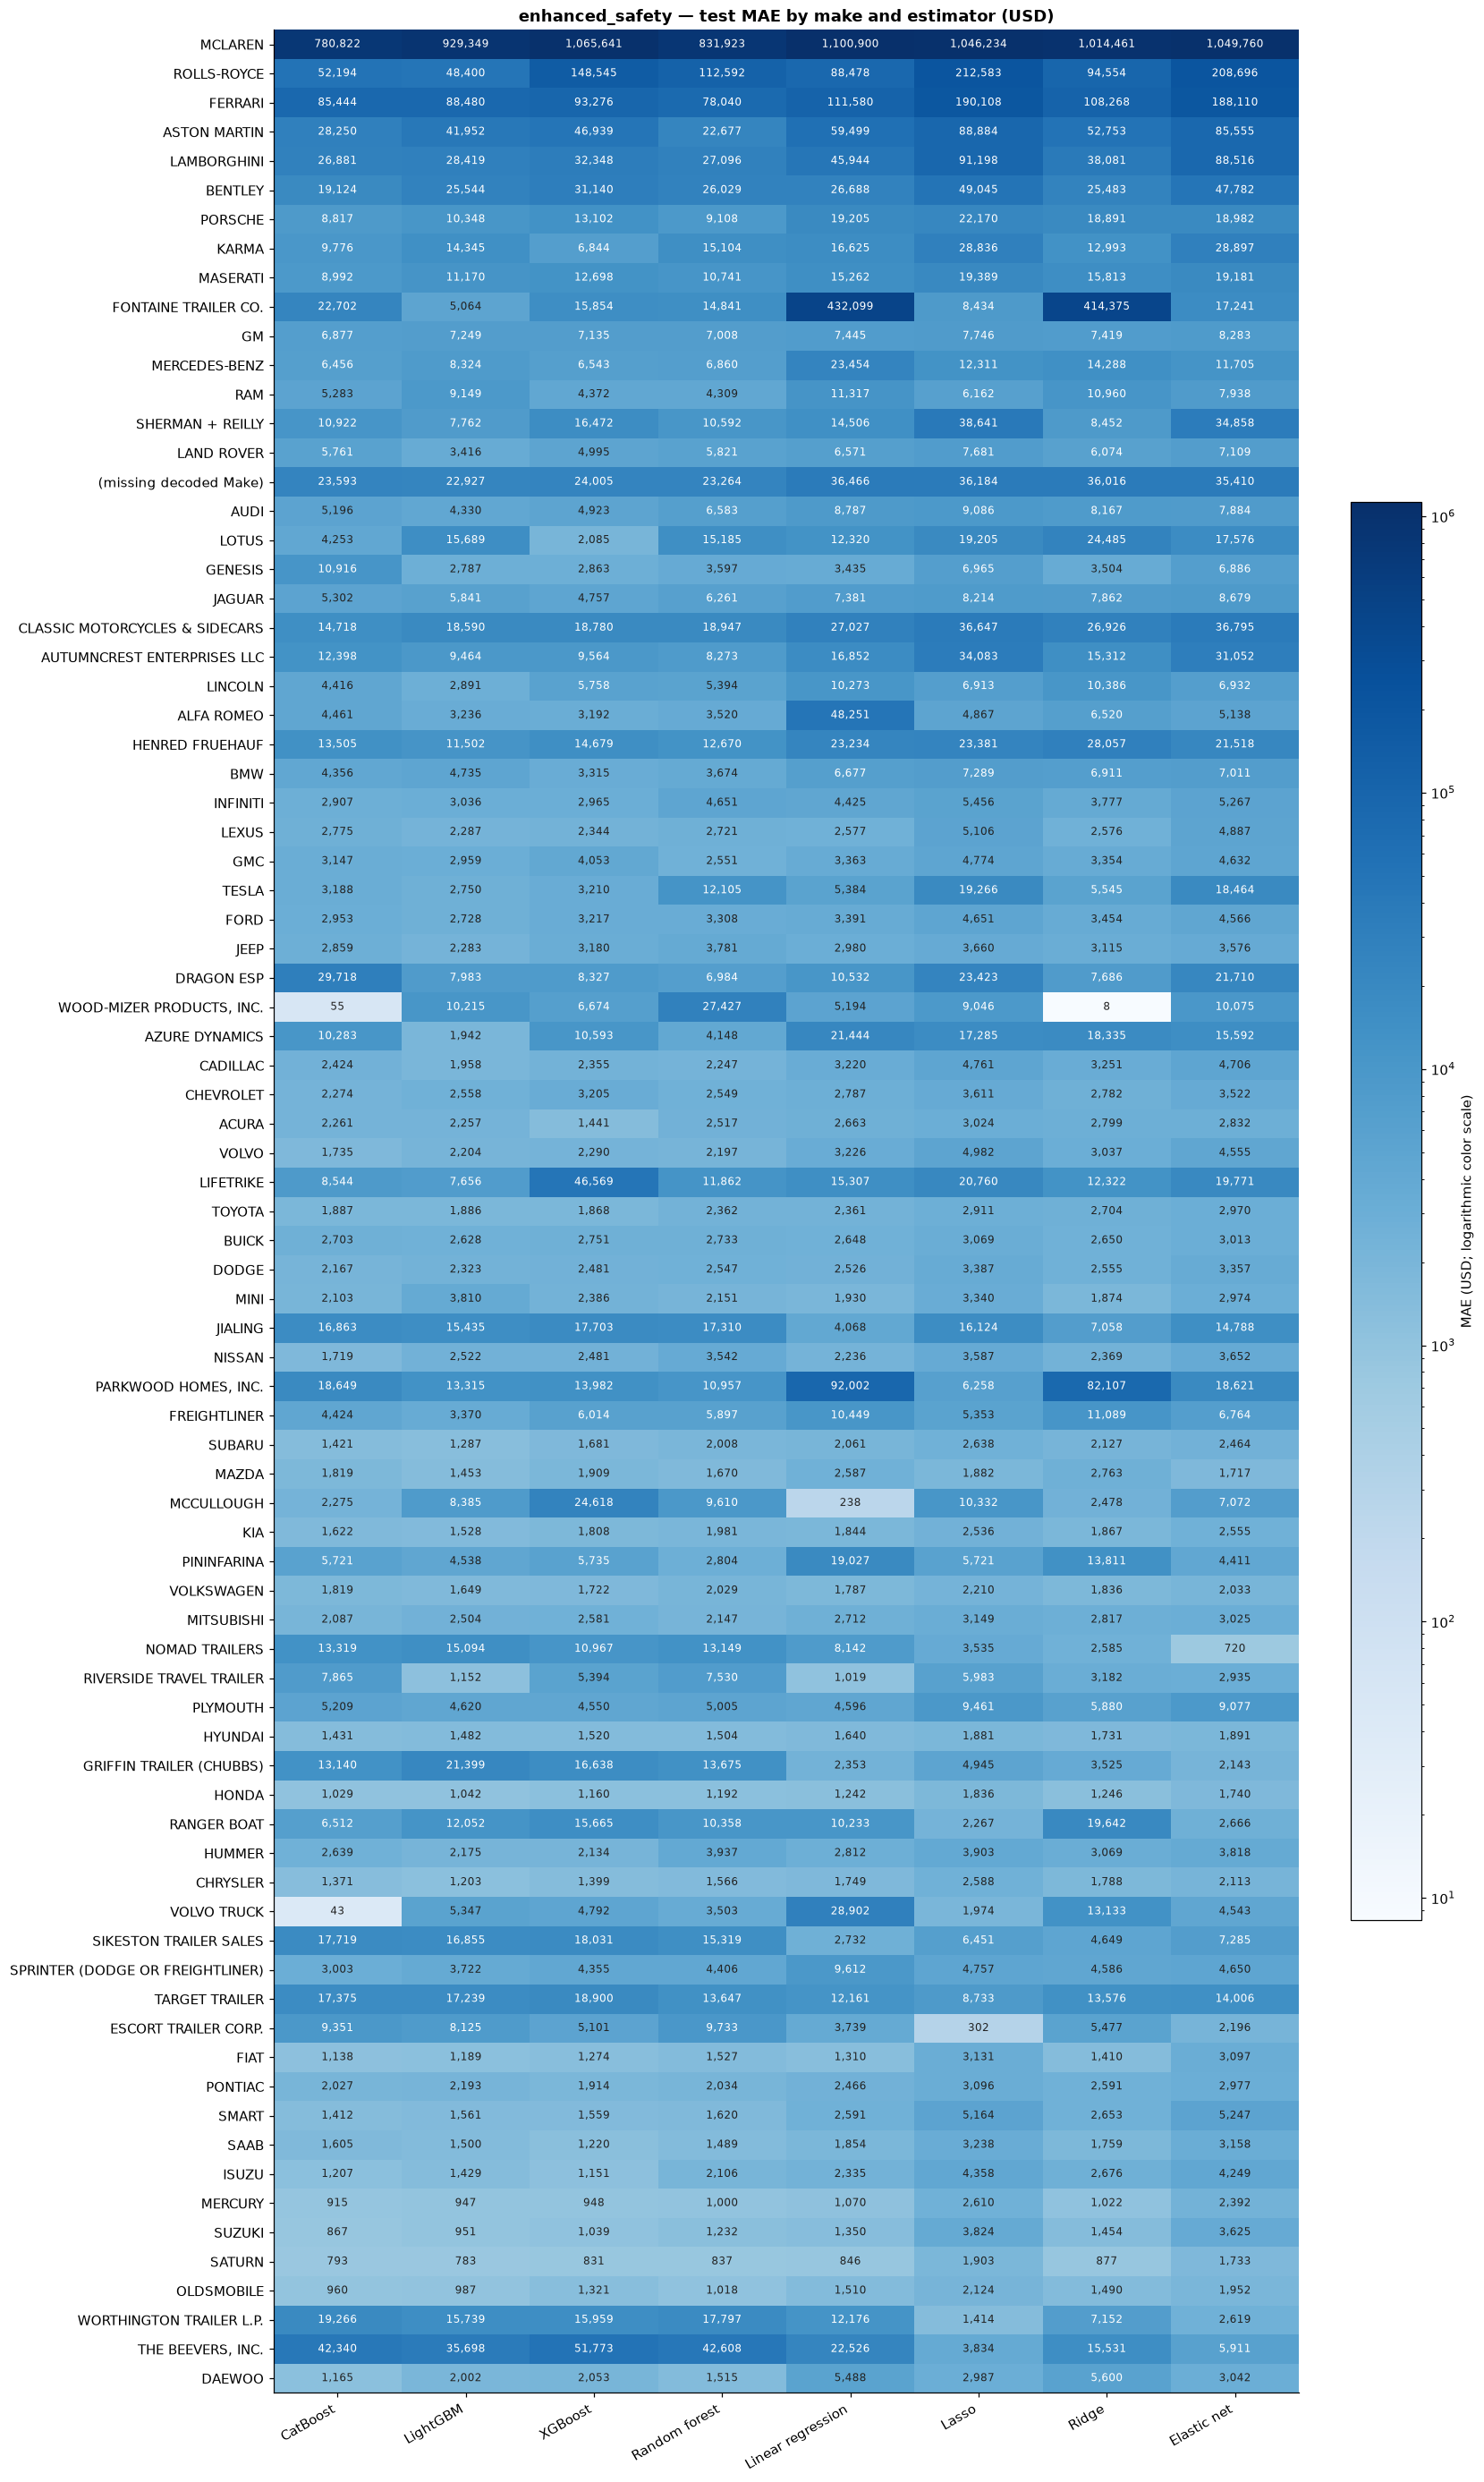

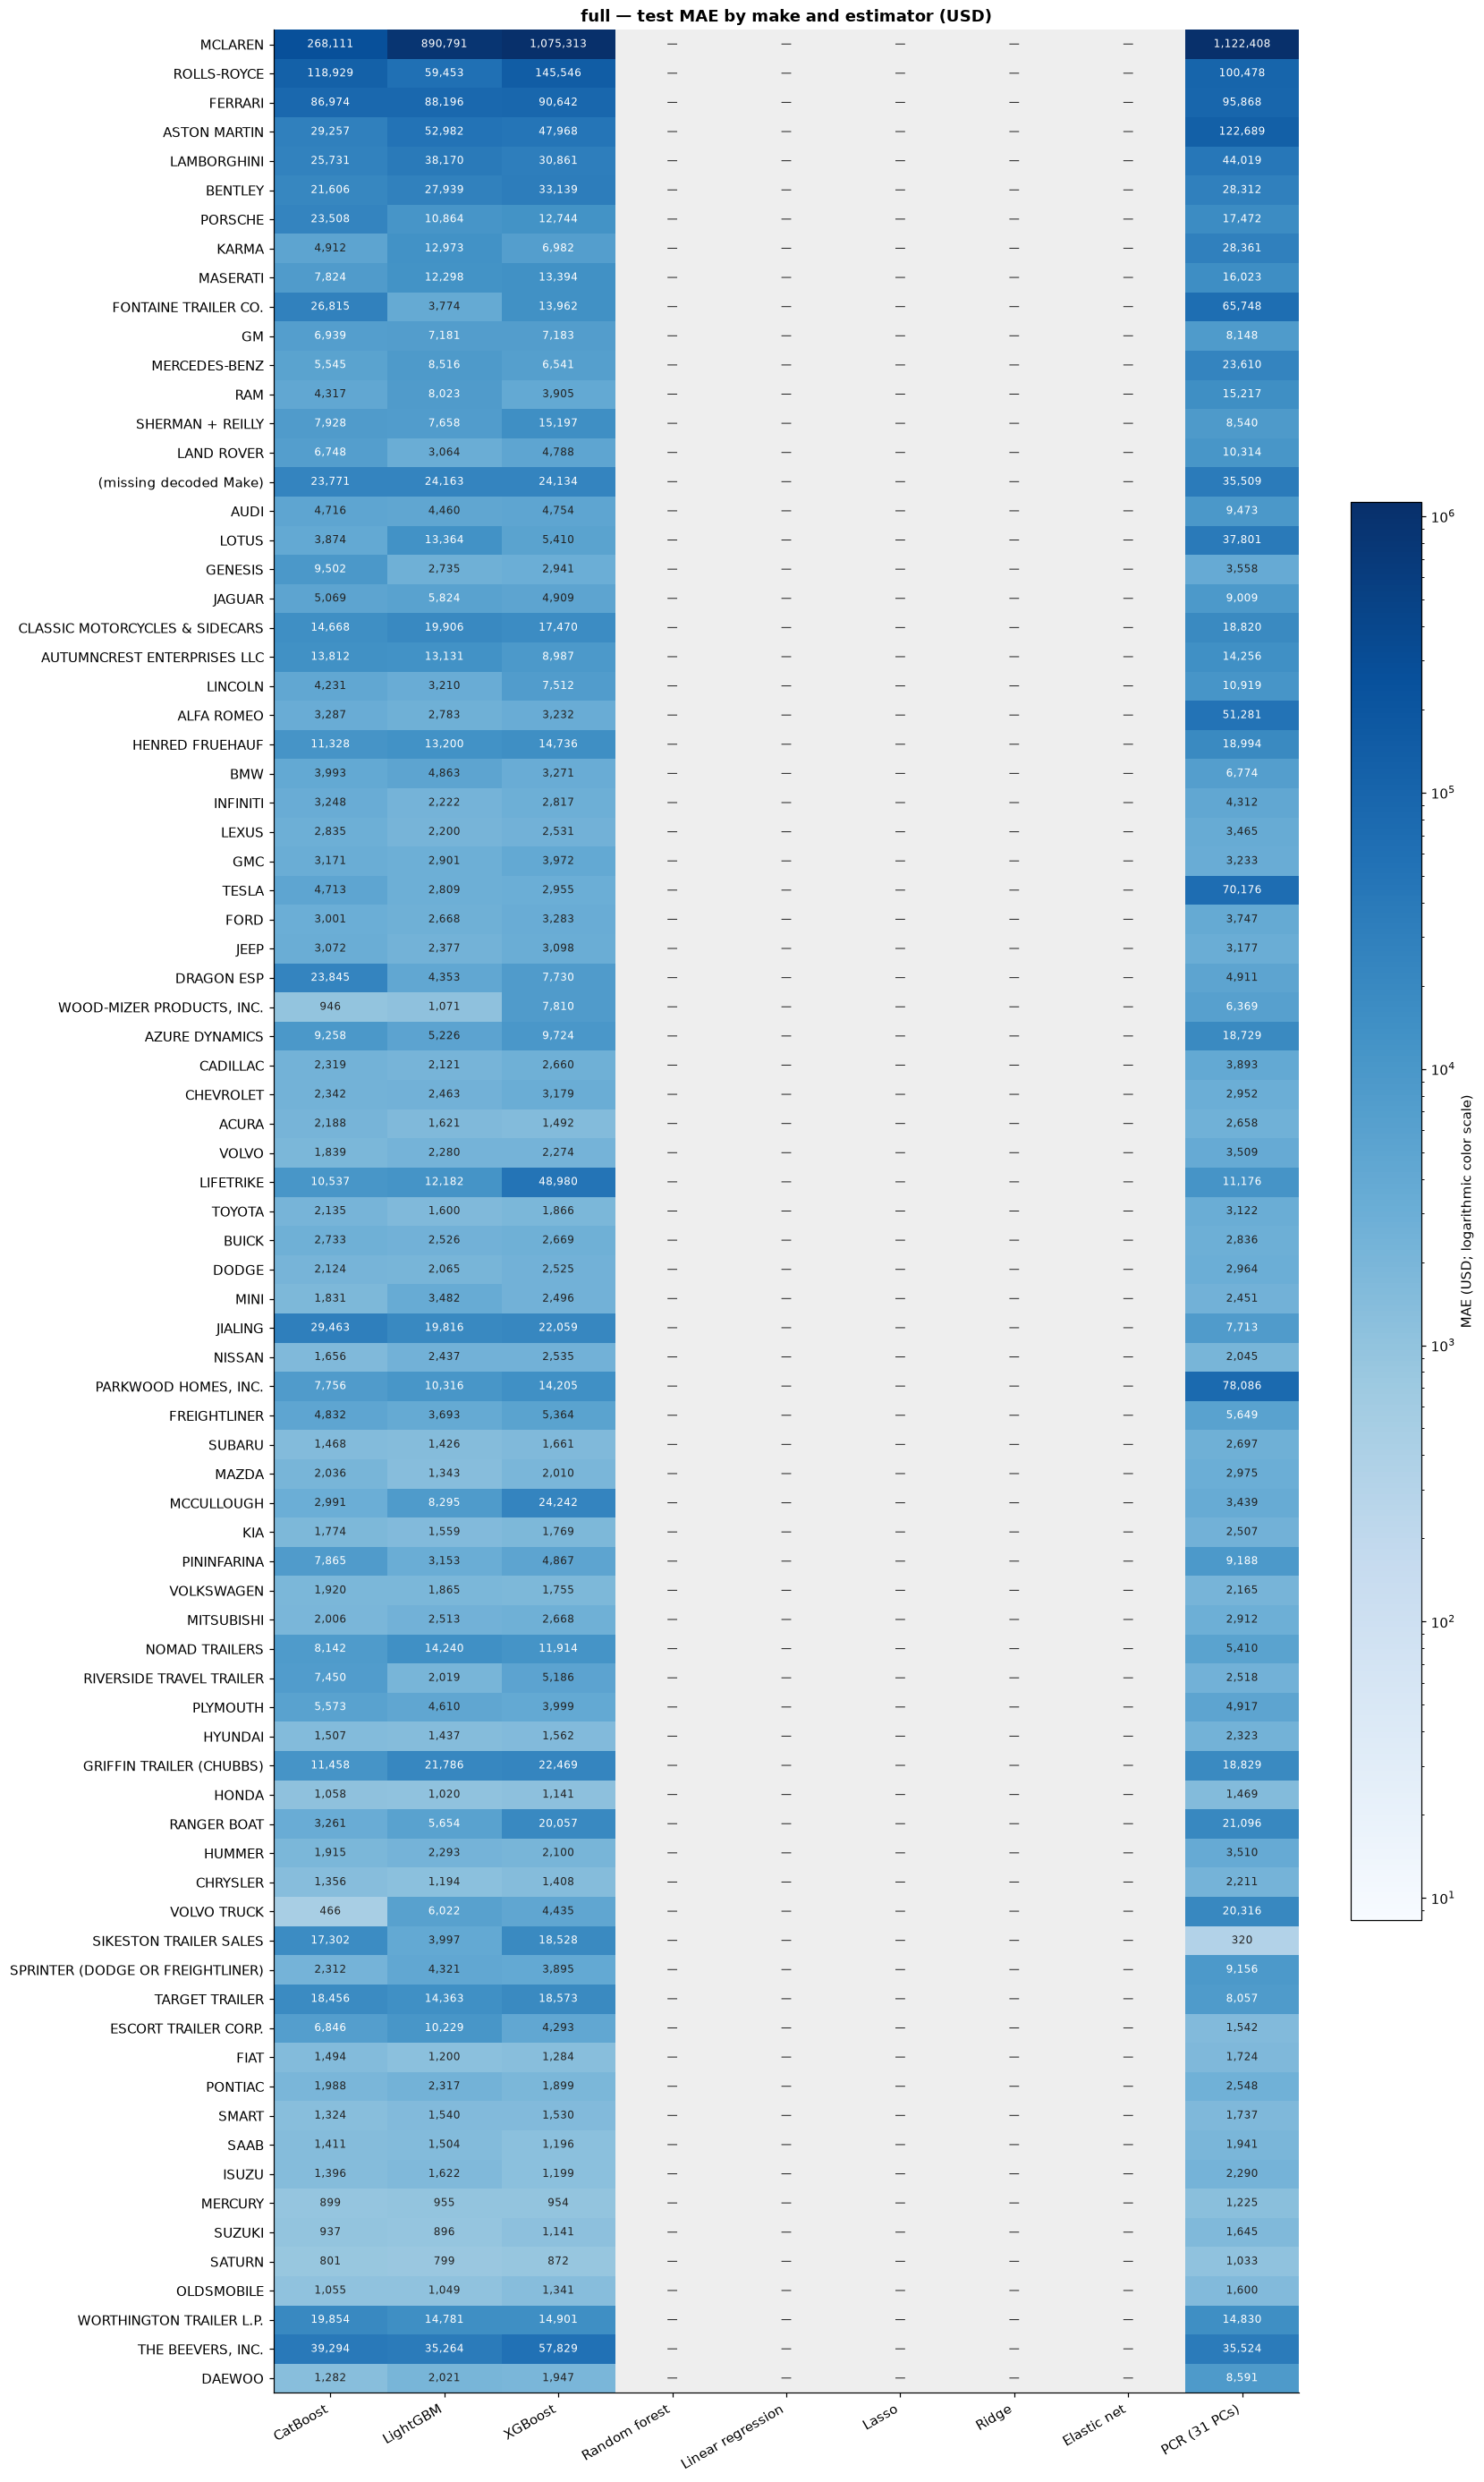

In [10]:
make_order = price_by_make.Make.tolist()
vmax = make_metrics.mae.max()
color_norm = LogNorm(vmin=make_metrics.loc[make_metrics.mae > 0, 'mae'].min(), vmax=vmax)
for variant in FEATURE_SETS:
    variant_models = models_for_variant(variant)
    part = make_metrics[make_metrics.feature_set == variant]
    matrix = part.pivot(index='Make', columns='model', values='mae').reindex(index=make_order, columns=variant_models)
    fig, ax = plt.subplots(figsize=(15, max(9, len(make_order) * .31)), constrained_layout=True)
    ax.set_facecolor('#eeeeee')
    im = ax.imshow(np.ma.masked_invalid(matrix.to_numpy()), aspect='auto', cmap='Blues', norm=color_norm)
    ax.set_xticks(range(len(variant_models)), [MODEL_LABELS[m] for m in variant_models], rotation=30, ha='right')
    ax.set_yticks(range(len(make_order)), make_order)
    ax.set_title(f'{variant} — test MAE by make and estimator (USD)')
    for (i, j), value in np.ndenumerate(matrix.to_numpy()):
        ax.text(j, i, '—' if pd.isna(value) else f'{value:,.0f}', ha='center', va='center',
                fontsize=8, color='white' if pd.notna(value) and color_norm(value) > .55 else '#222222')
    fig.colorbar(im, ax=ax, label='MAE (USD; logarithmic color scale)', shrink=.6)
    plt.show()

### Toyota versus Ferrari

The scatter uses all makes for the configured model. Open triangles mark low support. Log axes omit zero MAE; tables retain it. Different vehicle mixes limit interpretation.

,feature_set,model,Make,rows,family_blocks,mean_actual_price,mse,rmse,mae,r2,wape_pct,support_status
17,base,catboost,FERRARI,214,29,"252,334.01","86,964,170,391.03","294,896.88","78,524.27",0.118,31.12,supported
74,base,catboost,TOYOTA,"74,301",129,"27,409.58","5,304,149.88","2,303.07","1,609.20",0.966,5.87,supported
98,base,lightgbm,FERRARI,214,29,"252,334.01","95,718,571,400.44","309,384.18","88,092.88",0.030,34.91,supported
155,base,lightgbm,TOYOTA,"74,301",129,"27,409.58","6,453,890.16","2,540.45","1,807.86",0.959,6.60,supported
179,base,xgboost,FERRARI,214,29,"252,334.01","107,313,052,123.97","327,586.71","93,312.21",-0.088,36.98,supported
236,base,xgboost,TOYOTA,"74,301",129,"27,409.58","6,803,577.88","2,608.37","1,869.13",0.957,6.82,supported
260,base,random_forest,FERRARI,214,29,"252,334.01","94,903,581,798.05","308,064.25","81,479.82",0.038,32.29,supported
317,base,random_forest,TOYOTA,"74,301",129,"27,409.58","7,122,482.01","2,668.80","1,890.08",0.955,6.90,supported
341,base,multiple_linear_regression,FERRARI,214,29,"252,334.01","105,029,626,244.51","324,082.75","102,228.32",-0.065,40.51,supported
398,base,multiple_linear_regression,TOYOTA,"74,301",129,"27,409.58","22,430,174.09","4,736.05","2,754.41",0.857,10.05,supported


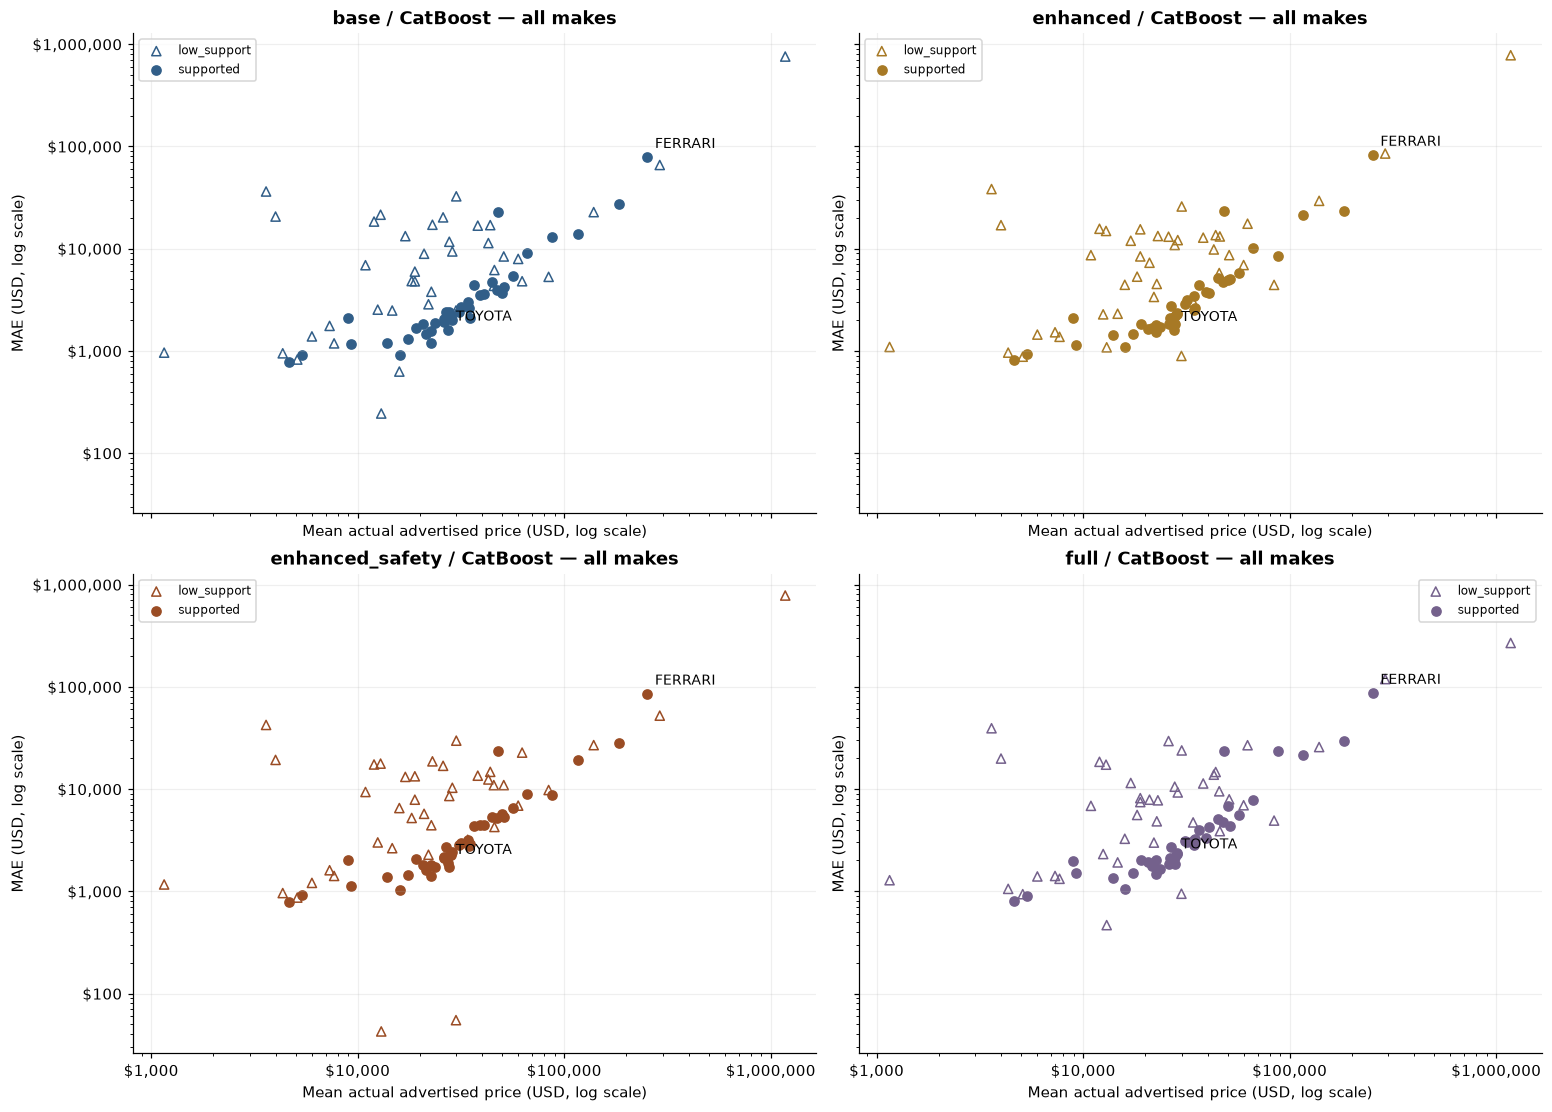

In [11]:
spotlight = make_metrics[make_metrics.Make.isin(SPOTLIGHT_MAKES)].copy()
display(formatted(spotlight[['feature_set', 'model', 'Make', 'rows', 'family_blocks',
    'mean_actual_price', 'mse', 'rmse', 'mae', 'r2', 'wape_pct', 'support_status']]))
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True, constrained_layout=True)
for ax, variant in zip(axes.flat, FEATURE_SETS):
    part = make_metrics[(make_metrics.feature_set == variant) & (make_metrics.model == MAKE_PLOT_MODEL)]
    if part.empty:
        ax.text(.5, .5, 'Pending', ha='center', transform=ax.transAxes)
        continue
    for support, group in part.groupby('support_status'):
        ax.scatter(group.mean_actual_price, group.mae, label=support,
                   marker='o' if support == 'supported' else '^',
                   facecolors=COLORS[variant] if support == 'supported' else 'none', edgecolors=COLORS[variant])
    for row in part[part.Make.isin(SPOTLIGHT_MAKES)].itertuples():
        ax.annotate(row.Make, (row.mean_actual_price, row.mae), xytext=(5, 6), textcoords='offset points', fontsize=9)
    ax.set_title(f'{variant} / {MODEL_LABELS[MAKE_PLOT_MODEL]} — all makes')
    ax.set_xlabel('Mean actual advertised price (USD, log scale)')
    ax.set_ylabel('MAE (USD, log scale)')
    ax.set_xscale('log')
    ax.set_yscale('log', nonpositive='mask')
    ax.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
    ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
plt.show()

### Exact make metrics

In [12]:
columns = ['Make', 'rows', 'family_blocks', 'mean_actual_price', 'median_actual_price',
           'mse', 'rmse', 'mae', 'r2', 'wape_pct', 'mean_signed_error', 'support_status']
for (variant, name), part in make_metrics.groupby(['feature_set', 'model'], sort=False):
    table = part[columns].sort_values('Make').to_html(index=False, na_rep='—', float_format=lambda v: f'{v:,.3f}')
    display(HTML(f'<details><summary>{variant} / {MODEL_LABELS[name]} — {len(part)} makes</summary>'
                 f'<div style="overflow-x:auto">{table}</div></details>'))

Make,rows,family_blocks,mean_actual_price,median_actual_price,mse,rmse,mae,r2,wape_pct,mean_signed_error,support_status
(missing decoded Make),444,205,"47,796.975","29,994.500","5,014,700,793.868","70,814.552","22,599.403",0.165,47.282,"-11,805.476",supported
ACURA,5033,30,"27,895.739","29,199.000","12,476,039.970","3,532.144","2,218.183",0.901,7.952,580.492,supported
ALFA ROMEO,2315,7,"39,280.605","39,295.000","18,884,040.583","4,345.577","3,486.769",0.809,8.877,"2,408.786",supported
ASTON MARTIN,196,13,"183,721.026","182,014.000","6,987,496,384.470","83,591.246","27,076.044",0.209,14.738,"-18,558.424",supported
AUDI,10514,73,"47,366.932","43,998.000","34,836,455.178","5,902.242","3,965.680",0.926,8.372,"-2,066.051",supported
AUTUMNCREST ENTERPRISES LLC,1,1,"42,900.000","42,900.000","128,350,148.288","11,329.172","11,329.172",—,26.408,"-11,329.172",low_support
AZURE DYNAMICS,1,1,"28,700.000","28,700.000","87,942,582.168","9,377.771","9,377.771",—,32.675,"-9,377.771",low_support
BENTLEY,140,18,"116,465.614","74,800.000","420,872,068.865","20,515.167","13,936.184",0.940,11.966,225.446,supported
BMW,8914,121,"36,471.092","37,412.500","59,245,470.510","7,697.108","4,457.032",0.889,12.221,"-2,854.113",supported
BUICK,20213,34,"26,690.630","26,390.000","9,403,319.915","3,066.483","2,406.491",0.853,9.016,311.729,supported


Make,rows,family_blocks,mean_actual_price,median_actual_price,mse,rmse,mae,r2,wape_pct,mean_signed_error,support_status
(missing decoded Make),444,205,"47,796.975","29,994.500","4,928,986,109.253","70,206.738","23,064.487",0.180,48.255,"-11,415.283",supported
ACURA,5033,30,"27,895.739","29,199.000","15,047,303.365","3,879.085","2,164.281",0.880,7.758,"-1,475.036",supported
ALFA ROMEO,2315,7,"39,280.605","39,295.000","12,974,849.790","3,602.062","2,655.415",0.869,6.760,-66.315,supported
ASTON MARTIN,196,13,"183,721.026","182,014.000","9,762,319,005.196","98,804.448","55,390.572",-0.106,30.149,"-43,671.896",supported
AUDI,10514,73,"47,366.932","43,998.000","52,493,456.290","7,245.237","4,195.171",0.889,8.857,"-2,493.993",supported
AUTUMNCREST ENTERPRISES LLC,1,1,"42,900.000","42,900.000","93,694,177.864","9,679.575","9,679.575",—,22.563,"-9,679.575",low_support
AZURE DYNAMICS,1,1,"28,700.000","28,700.000","5,801,762.366","2,408.685","2,408.685",—,8.393,"2,408.685",low_support
BENTLEY,140,18,"116,465.614","74,800.000","1,696,510,379.747","41,188.717","24,346.448",0.756,20.904,"-12,522.260",supported
BMW,8914,121,"36,471.092","37,412.500","49,068,878.633","7,004.918","3,980.942",0.908,10.915,"-2,353.825",supported
BUICK,20213,34,"26,690.630","26,390.000","11,675,824.092","3,416.991","2,578.404",0.818,9.660,30.502,supported


Make,rows,family_blocks,mean_actual_price,median_actual_price,mse,rmse,mae,r2,wape_pct,mean_signed_error,support_status
(missing decoded Make),444,205,"47,796.975","29,994.500","5,585,910,836.972","74,738.951","24,068.030",0.070,50.355,"-10,863.221",supported
ACURA,5033,30,"27,895.739","29,199.000","5,331,404.061","2,308.983","1,407.544",0.958,5.046,36.258,supported
ALFA ROMEO,2315,7,"39,280.605","39,295.000","17,281,356.198","4,157.085","3,331.183",0.825,8.480,259.059,supported
ASTON MARTIN,196,13,"183,721.026","182,014.000","9,062,512,267.482","95,197.228","48,185.098",-0.026,26.227,"-36,466.994",supported
AUDI,10514,73,"47,366.932","43,998.000","66,371,272.917","8,146.857","5,110.326",0.859,10.789,"-2,036.063",supported
AUTUMNCREST ENTERPRISES LLC,1,1,"42,900.000","42,900.000","105,689,081.832","10,280.520","10,280.520",—,23.964,"-10,280.520",low_support
AZURE DYNAMICS,1,1,"28,700.000","28,700.000","141,668,157.923","11,902.443","11,902.443",—,41.472,"-11,902.443",low_support
BENTLEY,140,18,"116,465.614","74,800.000","3,055,655,434.413","55,277.983","35,900.903",0.561,30.825,"-17,112.477",supported
BMW,8914,121,"36,471.092","37,412.500","52,804,967.040","7,266.703","3,302.503",0.901,9.055,-301.844,supported
BUICK,20213,34,"26,690.630","26,390.000","11,914,782.402","3,451.780","2,686.191",0.814,10.064,-212.029,supported


Make,rows,family_blocks,mean_actual_price,median_actual_price,mse,rmse,mae,r2,wape_pct,mean_signed_error,support_status
(missing decoded Make),444,205,"47,796.975","29,994.500","5,500,324,626.939","74,164.173","23,812.569",0.085,49.820,"-12,891.493",supported
ACURA,5033,30,"27,895.739","29,199.000","11,444,329.300","3,382.947","2,099.651",0.909,7.527,"-1,681.982",supported
ALFA ROMEO,2315,7,"39,280.605","39,295.000","31,712,719.275","5,631.405","4,633.454",0.679,11.796,"-1,741.374",supported
ASTON MARTIN,196,13,"183,721.026","182,014.000","8,354,283,476.759","91,401.770","26,705.208",0.054,14.536,"-22,600.421",supported
AUDI,10514,73,"47,366.932","43,998.000","69,367,614.626","8,328.722","5,303.283",0.853,11.196,"-3,721.403",supported
AUTUMNCREST ENTERPRISES LLC,1,1,"42,900.000","42,900.000","123,429,898.317","11,109.901","11,109.901",—,25.897,"-11,109.901",low_support
AZURE DYNAMICS,1,1,"28,700.000","28,700.000","8,480,158.780","2,912.071","2,912.071",—,10.147,"2,912.071",low_support
BENTLEY,140,18,"116,465.614","74,800.000","2,542,890,476.085","50,427.081","30,739.583",0.635,26.394,"-23,762.830",supported
BMW,8914,121,"36,471.092","37,412.500","53,959,784.232","7,345.732","3,916.389",0.899,10.738,"-1,637.042",supported
BUICK,20213,34,"26,690.630","26,390.000","13,439,313.175","3,665.967","2,767.536",0.790,10.369,-921.896,supported


Make,rows,family_blocks,mean_actual_price,median_actual_price,mse,rmse,mae,r2,wape_pct,mean_signed_error,support_status
(missing decoded Make),444,205,"47,796.975","29,994.500","6,998,021,116.929","83,654.176","34,641.989",-0.165,72.477,"-29,424.680",supported
ACURA,5033,30,"27,895.739","29,199.000","13,911,517.959","3,729.815","2,750.764",0.889,9.861,"-1,461.127",supported
ALFA ROMEO,2315,7,"39,280.605","39,295.000","32,932,027.812","5,738.643","4,783.185",0.667,12.177,-601.572,supported
ASTON MARTIN,196,13,"183,721.026","182,014.000","6,580,992,832.996","81,123.319","37,681.490",0.255,20.510,"-27,703.231",supported
AUDI,10514,73,"47,366.932","43,998.000","289,207,879.443","17,006.113","10,032.770",0.388,21.181,"-7,648.843",supported
AUTUMNCREST ENTERPRISES LLC,1,1,"42,900.000","42,900.000","1,504,906,831.968","38,793.129","38,793.129",—,90.427,"-38,793.129",low_support
AZURE DYNAMICS,1,1,"28,700.000","28,700.000","725,123,685.111","26,928.121","26,928.121",—,93.826,"-26,928.121",low_support
BENTLEY,140,18,"116,465.614","74,800.000","1,160,905,318.250","34,072.061","22,691.988",0.833,19.484,"-7,142.815",supported
BMW,8914,121,"36,471.092","37,412.500","58,500,220.811","7,648.544","5,714.028",0.890,15.667,"-1,923.288",supported
BUICK,20213,34,"26,690.630","26,390.000","12,543,383.051","3,541.664","2,758.485",0.804,10.335,-366.456,supported


...

Make,rows,family_blocks,mean_actual_price,median_actual_price,mse,rmse,mae,r2,wape_pct,mean_signed_error,support_status
(missing decoded Make),444,205,"47,796.975","29,994.500","7,103,600,432.157","84,282.860","35,410.381",-0.182,74.085,"-30,386.543",supported
ACURA,5033,30,"27,895.739","29,199.000","21,010,685.079","4,583.741","2,831.797",0.833,10.151,"-1,747.428",supported
ALFA ROMEO,2315,7,"39,280.605","39,295.000","41,367,809.870","6,431.781","5,137.852",0.581,13.080,"-3,079.988",supported
ASTON MARTIN,196,13,"183,721.026","182,014.000","14,683,889,853.947","121,177.101","85,554.948",-0.663,46.568,"-80,582.903",supported
AUDI,10514,73,"47,366.932","43,998.000","125,598,255.008","11,207.063","7,884.252",0.734,16.645,"-6,428.529",supported
AUTUMNCREST ENTERPRISES LLC,1,1,"42,900.000","42,900.000","964,234,314.478","31,052.123","31,052.123",—,72.383,"-31,052.123",low_support
AZURE DYNAMICS,1,1,"28,700.000","28,700.000","243,120,470.127","15,592.321","15,592.321",—,54.329,"-15,592.321",low_support
BENTLEY,140,18,"116,465.614","74,800.000","5,791,497,936.867","76,101.892","47,781.857",0.168,41.027,"-46,599.253",supported
BMW,8914,121,"36,471.092","37,412.500","131,561,571.001","11,470.029","7,011.420",0.753,19.225,"-3,114.893",supported
BUICK,20213,34,"26,690.630","26,390.000","15,916,846.717","3,989.592","3,013.474",0.752,11.290,"-1,108.996",supported


Make,rows,family_blocks,mean_actual_price,median_actual_price,mse,rmse,mae,r2,wape_pct,mean_signed_error,support_status
(missing decoded Make),444,205,"47,796.975","29,994.500","5,563,414,449.216","74,588.300","23,770.961",0.074,49.733,"-13,643.070",supported
ACURA,5033,30,"27,895.739","29,199.000","11,225,257.574","3,350.412","2,187.570",0.911,7.842,-557.798,supported
ALFA ROMEO,2315,7,"39,280.605","39,295.000","17,617,392.586","4,197.308","3,286.556",0.822,8.367,"2,383.534",supported
ASTON MARTIN,196,13,"183,721.026","182,014.000","7,109,125,332.235","84,315.629","29,257.246",0.195,15.925,"-16,527.666",supported
AUDI,10514,73,"47,366.932","43,998.000","54,163,095.386","7,359.558","4,715.849",0.885,9.956,"-3,316.218",supported
AUTUMNCREST ENTERPRISES LLC,1,1,"42,900.000","42,900.000","190,781,259.135","13,812.359","13,812.359",—,32.197,"-13,812.359",low_support
AZURE DYNAMICS,1,1,"28,700.000","28,700.000","85,710,864.739","9,258.016","9,258.016",—,32.258,"-9,258.016",low_support
BENTLEY,140,18,"116,465.614","74,800.000","1,832,614,220.355","42,809.044","21,606.312",0.737,18.552,"13,383.636",supported
BMW,8914,121,"36,471.092","37,412.500","47,999,192.049","6,928.145","3,993.045",0.910,10.949,"-2,248.916",supported
BUICK,20213,34,"26,690.630","26,390.000","13,292,763.313","3,645.924","2,732.801",0.793,10.239,-922.885,supported


Make,rows,family_blocks,mean_actual_price,median_actual_price,mse,rmse,mae,r2,wape_pct,mean_signed_error,support_status
(missing decoded Make),444,205,"47,796.975","29,994.500","5,156,646,502.349","71,809.794","24,163.286",0.142,50.554,"-11,635.882",supported
ACURA,5033,30,"27,895.739","29,199.000","11,683,691.003","3,418.141","1,620.755",0.907,5.810,-791.165,supported
ALFA ROMEO,2315,7,"39,280.605","39,295.000","12,359,150.299","3,515.558","2,782.869",0.875,7.085,78.691,supported
ASTON MARTIN,196,13,"183,721.026","182,014.000","9,285,593,730.453","96,361.786","52,982.338",-0.052,28.838,"-41,453.886",supported
AUDI,10514,73,"47,366.932","43,998.000","66,510,404.570","8,155.391","4,459.863",0.859,9.416,"-3,343.605",supported
AUTUMNCREST ENTERPRISES LLC,1,1,"42,900.000","42,900.000","172,424,918.661","13,131.067","13,131.067",—,30.609,"-13,131.067",low_support
AZURE DYNAMICS,1,1,"28,700.000","28,700.000","27,306,793.463","5,225.590","5,225.590",—,18.208,"5,225.590",low_support
BENTLEY,140,18,"116,465.614","74,800.000","2,124,056,916.156","46,087.492","27,938.752",0.695,23.989,"-16,098.218",supported
BMW,8914,121,"36,471.092","37,412.500","70,042,714.489","8,369.153","4,863.226",0.869,13.334,"-3,497.463",supported
BUICK,20213,34,"26,690.630","26,390.000","10,937,610.899","3,307.206","2,526.283",0.829,9.465,140.152,supported


Make,rows,family_blocks,mean_actual_price,median_actual_price,mse,rmse,mae,r2,wape_pct,mean_signed_error,support_status
(missing decoded Make),444,205,"47,796.975","29,994.500","5,621,455,895.376","74,976.369","24,133.627",0.064,50.492,"-11,393.335",supported
ACURA,5033,30,"27,895.739","29,199.000","5,859,441.179","2,420.628","1,491.838",0.953,5.348,-448.398,supported
ALFA ROMEO,2315,7,"39,280.605","39,295.000","15,994,923.832","3,999.365","3,231.780",0.838,8.227,"1,814.060",supported
ASTON MARTIN,196,13,"183,721.026","182,014.000","8,644,012,950.375","92,973.184","47,967.981",0.021,26.109,"-35,649.496",supported
AUDI,10514,73,"47,366.932","43,998.000","57,409,230.284","7,576.888","4,754.085",0.878,10.037,"-2,782.170",supported
AUTUMNCREST ENTERPRISES LLC,1,1,"42,900.000","42,900.000","80,768,977.462","8,987.156","8,987.156",—,20.949,"-8,987.156",low_support
AZURE DYNAMICS,1,1,"28,700.000","28,700.000","94,553,023.323","9,723.838","9,723.838",—,33.881,"-9,723.838",low_support
BENTLEY,140,18,"116,465.614","74,800.000","2,620,287,501.293","51,188.744","33,138.895",0.623,28.454,"-17,182.197",supported
BMW,8914,121,"36,471.092","37,412.500","25,275,276.300","5,027.452","3,270.702",0.953,8.968,"-1,284.750",supported
BUICK,20213,34,"26,690.630","26,390.000","11,522,704.367","3,394.511","2,668.810",0.820,9.999,-5.918,supported


Make,rows,family_blocks,mean_actual_price,median_actual_price,mse,rmse,mae,r2,wape_pct,mean_signed_error,support_status
(missing decoded Make),444,205,"47,796.975","29,994.500","6,409,893,523.311","80,061.811","35,509.484",-0.067,74.292,"-1,660.063",supported
ACURA,5033,30,"27,895.739","29,199.000","12,639,190.994","3,555.164","2,657.774",0.899,9.528,"-1,907.027",supported
ALFA ROMEO,2315,7,"39,280.605","39,295.000","7,269,270,967.355","85,260.020","51,281.474",-72.609,130.552,"51,119.296",supported
ASTON MARTIN,196,13,"183,721.026","182,014.000","28,060,320,245.513","167,512.150","122,689.463",-2.178,66.780,"-61,401.408",supported
AUDI,10514,73,"47,366.932","43,998.000","227,675,073.832","15,088.906","9,472.969",0.518,19.999,"-5,330.950",supported
AUTUMNCREST ENTERPRISES LLC,1,1,"42,900.000","42,900.000","203,246,465.258","14,256.453","14,256.453",—,33.232,"-14,256.453",low_support
AZURE DYNAMICS,1,1,"28,700.000","28,700.000","350,768,495.098","18,728.815","18,728.815",—,65.257,"-18,728.815",low_support
BENTLEY,140,18,"116,465.614","74,800.000","2,098,379,865.122","45,808.076","28,312.374",0.698,24.310,"-10,429.197",supported
BMW,8914,121,"36,471.092","37,412.500","77,283,477.128","8,791.102","6,774.013",0.855,18.574,"-2,807.733",supported
BUICK,20213,34,"26,690.630","26,390.000","13,536,599.752","3,679.212","2,836.211",0.789,10.626,"-1,314.385",supported


## 6. Interpretation and refresh

Select using validation; report test performance. Feature-set gains require paired uncertainty analysis. Rerun to discover checkpoints and refresh reports; hash-bound explanation caches are reused. Set `RUN_PREFLIGHT=True` for a fresh source audit.

## Appendix: source-data preflight

Read-only checks of the six Parquet sources write fresh reports under `MODEL_OUTPUT/diagnostics/`. Candidates are review flags, not exclusions. `listed_date + daysonmarket` is an unverified capture-date proxy; absent source rows do not establish zero events.

## 1. Setup

In [13]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'MODELS' / 'price_data_diagnostics.py').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'MODELS' / 'price_data_diagnostics.py').is_file():
    raise FileNotFoundError('Open this notebook from the project checkout or set PROJECT_ROOT to the checkout path.')
sys.path.insert(0, str(PROJECT_ROOT))
from MODELS.price_data_diagnostics import run_diagnostics

DATA_DIR = PROJECT_ROOT / 'DATA' / 'CAR_DATA_FINAL'
OUTPUT_ROOT = PROJECT_ROOT / 'MODEL_OUTPUT' / 'diagnostics'
# Main model-review setup above defines RUN_PREFLIGHT.


## 2. Run diagnostics

Review heuristics: price outside $500–$500,000; mileage outside 0–1,000,000; or price ≥10× family median with at least 20 listings. Thresholds do not change eligibility.

In [14]:
existing_preflights = sorted(p.parent for p in OUTPUT_ROOT.glob('*/diagnostic_run_metadata.json'))
if RUN_PREFLIGHT or not existing_preflights:
    diagnostic_dir = run_diagnostics(
        data_dir=DATA_DIR, output_dir=None, price_low=500, price_high=500_000,
        mileage_high=1_000_000, peer_ratio=10, peer_min_count=20, rare_count=20,
    )
else:
    diagnostic_dir = existing_preflights[-1]
print(f'Source preflight reports (may predate current model runs): {diagnostic_dir}')

Source preflight reports (may predate current model runs): E:\DataScience_Capstone_Cars\MODEL_OUTPUT\diagnostics\20260929T163158Z


## 3. Source inventory and listing scope

VIN is the vPIC join key, not a predictor.

In [15]:
inventory = pd.read_csv(diagnostic_dir / 'source_inventory.csv')
manifest_check = pd.read_csv(diagnostic_dir / 'export_manifest_check.csv')
scope = pd.read_csv(diagnostic_dir / 'listing_scope_and_value_summary.csv')
keys = pd.read_csv(diagnostic_dir / 'listing_key_quality.csv')
display(inventory[['table', 'exists', 'rows', 'columns', 'size_mib']])
display(manifest_check.T)
display(scope)
display(keys)

,table,exists,rows,columns,size_mib
0,used_cars,True,3000000,59,1242.26
1,nhtsa_vpic_decodes,True,2999875,133,22.23
2,nhtsa_complaints,True,1390528,17,239.59
3,nhtsa_recalls,True,26993,20,1.95
4,nhtsa_safety_rating_values,True,8144,35,0.26
5,youtube_comments_sentiment,True,1981686,12,166.87


,0
manifest_present,True
export_created_at_utc,2026-09-28T15:05:49.614727+00:00
tables_with_count_mismatch,0
mismatch_details,[]
note,Manifest row counts are checked against the cu...


,vehicle_scope,rows,distinct_vins_including_null,null_vins,non_17_character_vins,null_listing_id,null_price,null_mileage,null_year,price_min,...,mileage_p50,mileage_p90,mileage_p99,mileage_max,nonpositive_price_rows,price_below_500_rows,price_above_500k_rows,negative_mileage_rows,zero_mileage_rows,mileage_above_1m_rows
0,new,1471021,1471021,0,0,0,0,128099,0,8866,...,5.0,23.0,4263.0,99999988.0,0,0,21,0,256894,8
1,used,1528979,1528979,0,3052,0,0,16288,0,165,...,41167.0,127830.0,209000.0,400000.0,0,86,87,0,3,0


,key,source_rows,null_key_rows,duplicate_key_values,rows_with_a_duplicate_key,duplicate_row_rate
0,vin,3000000,0,0,0,0.0
1,listing_id,3000000,0,0,0,0.0


## 4. Missingness and cardinality

Profiles separate new/used/unknown listings. `major_options` receives cardinality checks only to avoid a huge rare-level table.

,vehicle_scope,feature,rows,missing_rows,missing_rate
0,new,owner_count,1471021,1470053,0.999342
1,new,theft_title,1471021,1424622,0.968458
2,new,fleet,1471021,1424622,0.968458
3,new,salvage,1471021,1424622,0.968458
4,new,frame_damaged,1471021,1424622,0.968458
5,new,has_accidents,1471021,1424622,0.968458
6,new,city_fuel_economy,1471021,251050,0.170664
7,new,highway_fuel_economy,1471021,251050,0.170664
8,new,listing_color,1471021,236123,0.160516
9,new,interior_color,1471021,144551,0.098266


,feature,used_nonmissing_rows,raw_distinct_levels,normalized_distinct_levels,levels_at_or_below_rare_count,rows_in_rare_levels,rare_count_threshold
0,major_options,1461052,191865,191865,NaN,NaN,NaN
1,interior_color,1528974,18412,15481,14182.0,37141.0,20.0
2,exterior_color,1528979,18460,14912,12753.0,38399.0,20.0
3,trim_name,1486896,8780,8736,5455.0,30726.0,20.0
4,model_name,1528979,1419,1418,568.0,3116.0,20.0
5,listing_color,1528979,15,15,0.0,0.0,20.0


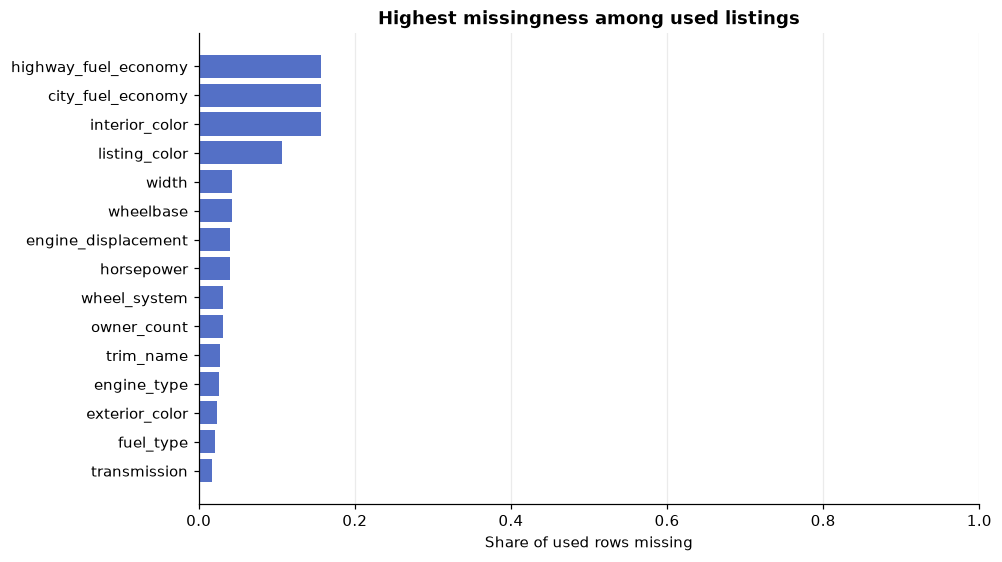

In [16]:
missingness = pd.read_csv(diagnostic_dir / 'base_feature_missingness.csv')
cardinality = pd.read_csv(diagnostic_dir / 'used_category_cardinality.csv')
display(missingness.sort_values(['vehicle_scope', 'missing_rate'], ascending=[True, False]).groupby('vehicle_scope').head(12))
display(cardinality)

if not missingness.empty:
    used_missing = missingness[missingness.vehicle_scope == 'used'].nlargest(15, 'missing_rate')
    fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
    ax.barh(used_missing.feature[::-1], used_missing.missing_rate[::-1], color='#5470C6')
    ax.set_title('Highest missingness among used listings')
    ax.set_xlabel('Share of used rows missing')
    ax.set_xlim(0, 1)
    ax.grid(axis='x', alpha=.25)
    plt.show()

## 5. VIN linkage and identity

Join on lowercase `vin` with no row expansion. Listing/decoder disagreements can reflect naming granularity.

In [17]:
join_summary = pd.read_csv(diagnostic_dir / 'vin_join_and_identity_summary.csv')
display(join_summary.T)
mismatch_path = diagnostic_dir / 'used_listing_vpic_name_mismatch_sample.csv'
if mismatch_path.exists():
    display(pd.read_csv(mismatch_path).head(30))
else:
    display(Markdown('No mismatch sample was written; check the join summary for a skipped join or zero disagreements.'))

,0
check,listing to vPIC VIN join
status,passed
listing_rows,3000000
distinct_listing_vins,3000000
distinct_listing_ids,3000000
vpic_distinct_vins,2999875
join_rows,3000000
matched_listing_rows,2999875
unmatched_listing_rows,125
missing_ModelYear_rows,3643


,vin,listing_id,is_new,year,ModelYear,make_name,Make,model_name,Model,Trim,ErrorCode
0,JF1VA2M67G9829723,173473508,False,2016,2016.0,Subaru,SUBARU,WRX STI,WRX,STi,0
1,WBA8B7C53GK368522,173473505,False,2016,2016.0,BMW,BMW,3 Series,340i,xDrive,0
2,JTHSZ5BC5J5008777,278352194,False,2018,2018.0,Lexus,LEXUS,RC 350,RC,350,0
3,1C4BJWDG9EL260645,277512563,False,2014,2014.0,Jeep,JEEP,Wrangler Unlimited,Wrangler,Sport,0
4,1C4HJXEG5JW173011,280678802,False,2018,2018.0,Jeep,JEEP,Wrangler Unlimited,Wrangler,Unlimited Sahara,0
5,2GCVKREC6J1108622,279129183,False,2018,2018.0,Chevrolet,CHEVROLET,Silverado 1500,Silverado,LT,0
6,1C4BJWEG1CL149406,279565009,False,2012,2012.0,Jeep,JEEP,Wrangler Unlimited,Wrangler,Sahara,0
7,2T2BZMCA1HC089777,280652001,False,2017,2017.0,Lexus,LEXUS,RX 350,RX,350,0
8,1GCVKREC8HZ136438,276184104,False,2017,2017.0,Chevrolet,CHEVROLET,Silverado 1500,Silverado,LT,0
9,WBA4B3C59FD670181,279775078,False,2015,2015.0,BMW,BMW,4 Series,435i,xDrive GC,0


## 6. Date availability

Events after the capture-date proxy indicate possible future-information exposure. Safety publication dates are unavailable; YouTube has no listing/VIN key.

In [18]:
date_path = diagnostic_dir / 'listing_date_profile.csv'
if date_path.exists(): display(pd.read_csv(date_path))
display(pd.read_csv(diagnostic_dir / 'date_proxy_notes.csv'))
display(pd.read_csv(diagnostic_dir / 'nhtsa_event_date_profile.csv'))
display(pd.read_csv(diagnostic_dir / 'issue_availability_vs_date_proxy.csv'))
display(pd.read_csv(diagnostic_dir / 'safety_source_profile.csv'))

,vehicle_scope,rows,listed_date_min,listed_date_max,unparsed_or_missing_listed_date_rows,daysonmarket_min,daysonmarket_max,unparsed_or_missing_daysonmarket_rows,observation_date_proxy_min,observation_date_proxy_max
0,new,1471021,2017-06-25,2020-09-12,0,0,1174,0,2020-09-09,2020-09-17
1,used,1528979,2010-11-03,2020-09-13,0,0,3599,0,2020-09-09,2020-09-17


,check,status,detail
0,listing date proxy,profiled,"listed_date + daysonmarket is a proxy, not a v..."


,source,date_field,status,rows,date_min,date_max,missing_date_rows
0,nhtsa_complaints,dateComplaintFiled,profiled,1390528,1984-02-16,2026-09-23,0
1,nhtsa_recalls,ReportReceivedDate,profiled,26993,1966-01-19,2026-09-17,0


,source,status,date_field,used_rows_with_proxy,rows_with_source_records,rows_with_later_source_records,latest_source_date_in_joined_keys,interpretation
0,nhtsa_complaints,profiled against date proxy,dateComplaintFiled,1528979,1301219,1291515,2026-09-23,Potential future-information exposure only; th...
1,nhtsa_recalls,profiled against date proxy,ReportReceivedDate,1528979,1258848,822586,2026-09-17,Potential future-information exposure only; th...


,rows,missing_overall_rating_rows,minimum_model_year,maximum_model_year
0,8144,5505,1990,2021


## 7. Review candidates

Confirm source errors before changing eligibility. Peer medians use year/make/model families; all four decoded cohort dimensions remain on candidate rows.

In [19]:
review_summary = pd.read_csv(diagnostic_dir / 'used_label_and_mileage_review_summary.csv')
candidates_path = diagnostic_dir / 'used_listing_review_candidates.csv'
display(review_summary)
if candidates_path.exists():
    candidates = pd.read_csv(candidates_path)
    display(candidates.head(100))
    print(f'{len(candidates):,} candidate rows; full file: {candidates_path}')
else:
    display(Markdown('Candidate file was not created; check the diagnostic metadata and join status.'))

,candidate_rows,price_below_threshold_rows,price_above_threshold_rows,high_vs_peer_family_rows,mileage_out_of_range_rows,zero_mileage_review_rows,policy
0,210,86,87,49,0,3,review heuristics only; no rows excluded or ch...


,vin,listing_id,price,mileage,year,ModelYear,Make,Model,Trim,make_name,...,daysonmarket,peer_family_price_median,peer_family_listing_count,price_to_peer_family_median,price_below_threshold_flag,price_above_threshold_flag,peer_price_review_flag,mileage_out_of_range_flag,zero_mileage_review_flag,review_reasons
0,WDDAK76FX9M001946,216987621,859000,1379.0,2009,2009.0,MERCEDES-BENZ,NaN,NaN,Mercedes-Benz,...,743,NaN,NaN,NaN,False,True,NaN,False,False,price_above_threshold
1,1563,254703927,1390000,1348.0,1959,NaN,NaN,NaN,NaN,Ferrari,...,335,NaN,NaN,NaN,False,True,NaN,False,False,price_above_threshold
2,ZFF72RHA2B0181343,268724936,1299950,1258.0,2011,2011.0,FERRARI,NaN,NaN,Ferrari,...,178,NaN,NaN,NaN,False,True,NaN,False,False,price_above_threshold
3,ZFF83CLA5L0249674,272884491,529997,210.0,2020,2020.0,FERRARI,812,NaN,Ferrari,...,103,399900.0,13.0,1.325324,False,True,False,False,False,price_above_threshold
4,3N1AB7AP8EY292080,281592028,111111,42215.0,2014,2014.0,NISSAN,Sentra,NaN,Nissan,...,0,7999.0,537.0,13.890611,False,False,True,False,False,high_vs_peer_family
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,2G4WS52M4X1536882,281504256,165,190000.0,1999,1999.0,BUICK,Century,Custom,Buick,...,4,2900.0,17.0,0.056897,True,False,False,False,False,price_below_threshold
96,1B3EJ46X6VN687351,275269396,484,162000.0,1997,1997.0,DODGE,Stratus,Base,Dodge,...,74,1489.5,2.0,0.324941,True,False,False,False,False,price_below_threshold
97,2B4GP2534YR737516,277059405,484,198751.0,2000,2000.0,DODGE,Caravan/Grand Caravan,Base,Dodge,...,53,2995.0,18.0,0.161603,True,False,False,False,False,price_below_threshold
98,1G1JC524XY7248258,277323803,484,85332.0,2000,2000.0,CHEVROLET,Cavalier,NaN,Chevrolet,...,49,2970.0,22.0,0.162963,True,False,False,False,False,price_below_threshold


210 candidate rows; full file: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\diagnostics\20260929T163158Z\used_listing_review_candidates.csv


## 8. Review decisions

Resolve listing grain, unknown condition, flagged labels, and historical feature availability before changing the benchmark. Preserve dispositions with `diagnostic_run_metadata.json`.